# Práctica PLN mediante Deep Learning 26/27 — Multi-Author Writing Style Analysis (PAN 2026)

**Integrantes de la pareja**
- Sergio del Barco
- Jorge Comesaña

## Tabla resumen de experimentos

> F1-macro sobre el conjunto de **test** (métrica oficial de PAN, calculada por separado para cada dificultad). La última celda del notebook imprime esta tabla con los valores reales para copiarla aquí.

| # | Iteración | Experimento | Entrenamiento | F1 easy | F1 medium | F1 hard | F1 medio | Conclusión |
|---|---|---|---|---|---|---|---|---|
| 0 | — | Baseline: siempre «sin cambio» | — | 0,4100 | 0,4889 | 0,4411 | 0,4467 | Cota inferior trivial. |
| 1 | — | Baseline: aleatorio estratificado | Tasa de cambios de train | 0,4984 | 0,4993 | 0,5004 | 0,4994 | El azar informado da F1 ≈ 0,5 en las tres dificultades. |
| 2 | 1 | RoBERTa-base pares, umbral 0,5 | 40.000 pares/dif. (distribución natural), 2 épocas, pesos de clase | 0,9553 | 0,6270 | 0,7014 | 0,7612 | *Easy* casi resuelto. En *medium* y *hard* se pierde más de la mitad de los cambios (FN). |
| 3 | 1 | Ídem + umbral global (0,68) | Ídem | 0,9609 | 0,6384 | 0,6921 | 0,7638 | Un único umbral no sirve: mejora *easy* y *medium* pero empeora *hard*. |
| 4 | 1 | Ídem + umbral por dificultad (0,94 / 0,85 / 0,32) | Ídem | 0,9745 | 0,6454 | 0,7117 | 0,7772 | Mejor resultado de la iteración 1. Umbrales tan distintos indican que el modelo no está calibrado por dificultad. |
| 5 | 2 | RoBERTa-base v2 (más positivos, más datos distintos, 1 época, cabeza fp32), umbral 0,5 | 80.000 pares/dif. con 35 % de cambios, 1 época, sin pesos de clase | 0,9661 | 0,5998 | 0,7100 | 0,7586 | Con umbral 0,5 empeora *medium*: entrenar con un 35 % de cambios desplaza el *prior* (en *medium* real hay un 4 %) y aumenta los FP. Hay que recalibrar el umbral. |
| 6 | 2 | Ídem + umbral global (0,65) | Ídem | 0,9726 | 0,6372 | 0,6959 | 0,7686 | Como en la it. 1, un único umbral mejora *easy* y *medium* a costa de *hard*. |
| 7 | 2 | Ídem + umbral por dificultad (0,82 / 0,90 / 0,26) | Ídem | 0,9767 | 0,6736 | 0,7290 | 0,7931 | Mejora a la it. 1 en las tres dificultades (+1,6 puntos de F1 medio) y reduce los FN de *hard* del 50 % al 45 %. Los umbrales siguen muy separados. |
| 8 | 3 | RoBERTa-base v3 (v2 + dificultad como prefijo de la entrada), umbral 0,5 | Ídem v2 | 0,9970 | 0,6208 | 0,7299 | 0,7825 | Sin ajustar el umbral ya supera a la it. 2 con umbral 0,5 en 2,4 puntos: conocer la dificultad corrige buena parte de la descalibración. |
| 9 | 3 | Ídem + umbral global (0,72) | Ídem | 0,9970 | 0,6754 | 0,7142 | 0,7956 | Un solo umbral ya iguala al mejor resultado de la it. 2 (que necesitaba tres). |
| 10 | 3 | Ídem + umbral por dificultad (0,98 / 0,82 / 0,54) | Ídem | 0,9974 | 0,6802 | 0,7311 | 0,8029 | *Easy* queda prácticamente resuelto. *Medium* y *hard* apenas mejoran (+0,7 y +0,2 puntos): el límite está en la poca señal de estilo de dos oraciones sueltas. |
| 11 | 4 | 2º nivel: *gradient boosting* sobre p(it. 3) + 149 rasgos de estilo, tema y contexto del documento, umbral 0,5 | Entrenado con la validación completa (CV de 5 *folds* agrupada por documento) | 0,9992 | 0,6621 | 0,7223 | 0,7946 | El umbral 0,5 ya no es el adecuado: el 2º nivel aprende la tasa real de cambios (4 % en *medium*), y para el F1-macro conviene un umbral más bajo. |
| 12 | 4 | Ídem + umbral global (0,30) | Ídem | 0,9992 | 0,7003 | 0,7382 | 0,8126 | Un único umbral ya supera a la it. 3 con tres umbrales (+1,0 punto). |
| 13 | 4 | Ídem + umbral por dificultad (0,53 / 0,24 / 0,35) | Ídem | 0,9993 | 0,7022 | 0,7418 | 0,8144 | Mejor resultado hasta aquí, sin reentrenar RoBERTa: *medium* +2,2 y *hard* +1,1 puntos sobre la it. 3. El contexto del documento ayuda en *medium*; el estilo explícito, en *medium* y *hard*. |
| 14–16 | 5 | 2º nivel + juicios de RoBERTa sobre pares **no consecutivos** que cruzan la frontera (distancias 2 y 3) + segunda pasada | Ídem (inferencia extra, sin reentrenar RoBERTa) | _pend._ | _pend._ | _pend._ | _pend._ | _pend._ |

## Metodología experimental

1. **Tarea**: el problema se plantea como una **clasificación binaria de pares de oraciones consecutivas**, en la que hay que decidir si hay cambio de autor (`1`) o no (`0`) entre la oración *i* y la *i+1*.
2. **Métrica**: F1-macro sobre todos los pares de cada dificultad (*easy*, *medium* y *hard*), igual que el evaluador oficial de PAN. También se da la media de las tres.
3. **Particiones**:
   - `train` se usa para entrenar, con un submuestreo de pares por limitación de hardware.
   - `validation` sirve para elegir el checkpoint (con un subconjunto) y para ajustar el umbral de decisión (con el conjunto completo).
   - `test` **solo** se usa para la evaluación final.
4. **Reproducibilidad**: semilla fija (`SEED = 42`) y todos los hiperparámetros en una única celda de configuración.
5. **Hardware**: GPU RTX 3050 Laptop de 4 GB. Se aplican las técnicas del cuaderno de optimización (precisión mixta bf16, TF32, atención SDPA, AdamW fusionado, *padding* dinámico con agrupación por longitud, acumulación de gradiente y elección del tamaño de batch midiendo memoria). También se miden el tiempo y la memoria de cada fase.
6. **Comparación**: los modelos se comparan contra los baselines triviales de este notebook y contra los resultados publicados de PAN para la misma tarea.
7. **Proceso iterativo**: cada iteración parte del **diagnóstico de errores** de la anterior en validación (nunca en test) y cambia lo justificado por ese diagnóstico. Las iteraciones anteriores **se conservan en el notebook** con sus resultados, y cada cambio se documenta en una tabla «antes → ahora → por qué».
   - **Iteración 1** (secciones 4–6): *cross-encoder* RoBERTa-base de referencia.
   - **Iteración 2** (sección 8): corrige los falsos negativos de *medium* y *hard* tocando los datos de entrenamiento y la precisión de la cabeza.
   - **Iteración 3** (sección 9): condiciona el modelo a la dificultad.
   - **Iteración 4** (secciones 10–11): tras diagnosticar los errores de la iteración 3, un modelo de segundo nivel combina la probabilidad de RoBERTa con rasgos de estilo explícitos y el contexto del documento.
   - **Iteración 5** (sección 12): el mismo RoBERTa juzga también pares de oraciones **no consecutivas** que cruzan cada frontera. Así cada decisión se apoya en varios juicios independientes, sin mezclar autores en una misma entrada.

## 0. Descripción de la tarea y de los datos

**Multi-Author Writing Style Analysis 2026**: dado un documento escrito por uno o varios autores, hay que detectar **en qué posiciones cambia el autor**, a nivel de oración.

El dataset `mawsa_full_dataset` tiene tres niveles de dificultad:

| Dificultad | Qué la caracteriza |
|---|---|
| `easy` | Las oraciones de distintos autores tratan temas distintos, así que el tema ayuda. |
| `medium` | La variedad temática es pequeña: hay que fijarse más en el estilo. |
| `hard` | Todas las oraciones tratan el mismo tema: solo queda el estilo. |

Cada nivel tiene `train`, `validation` y `test`. Cada problema consta de:
- `problem-N.txt`: una oración por línea.
- `truth-problem-N.json`: `{"authors": k, "changes": [...]}`, con `len(changes) = nº oraciones − 1`.

> **Nota sobre la carga.** Los datos se leen de la carpeta `full_dataset/` (el zip original descomprimido). Leer ~90.000 ficheros pequeños en Windows es lento de forma secuencial, por eso la lectura se hace **en paralelo con hilos** y el resultado se guarda en caché. Se comprueba además que los `.txt` no sean *punteros de Git LFS* (`version https://git-lfs...`), que fue un problema real en una versión anterior del repositorio. Si la carpeta no existe, el cargador lee directamente de `mawsa_full_dataset.zip`.

## 1. Entorno

In [46]:
# Librerías
# En Windows, torch debe importarse ANTES que numpy/matplotlib/sklearn: si no, puede fallar la carga
# de sus DLLs (OSError WinError 1114 al cargar c10.dll)
import torch
import os
import gc
import re
import json
import math
import time
import random
import itertools
import zipfile
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "true")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import transformers
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from tqdm.auto import tqdm

transformers.logging.set_verbosity_error()
pd.set_option("display.max_colwidth", 120)
print(f"torch {torch.__version__} | transformers {transformers.__version__} | pandas {pd.__version__}")

torch 2.14.1+cu126 | transformers 5.20.2 | pandas 2.3.3


In [47]:
# GPU: comprobamos qué soporta (igual que en el cuaderno de optimización)
assert torch.cuda.is_available(), "Este notebook necesita una GPU con CUDA"
device = torch.device("cuda")

GPU_NAME = torch.cuda.get_device_name(0)
CAPABILITY = torch.cuda.get_device_capability(0)
GPU_MEMORY_GB = torch.cuda.get_device_properties(0).total_memory / 1024**3
IS_AMPERE_OR_NEWER = CAPABILITY >= (8, 0)
# bfloat16 tiene el mismo rango que float32 -> no necesita GradScaler. En GPUs anteriores a Ampere: float16 + loss scaling
AMP_DTYPE = torch.bfloat16 if IS_AMPERE_OR_NEWER else torch.float16

# TF32: las multiplicaciones de matrices en float32 que queden fuera de autocast usan tensor cores
torch.set_float32_matmul_precision("high")

print(f"GPU: {GPU_NAME} | compute capability {CAPABILITY} | {GPU_MEMORY_GB:.1f} GB")
print(f"Precisión mixta: {AMP_DTYPE}")

GPU: NVIDIA GeForce RTX 3050 Laptop GPU | compute capability (8, 6) | 4.0 GB
Precisión mixta: torch.bfloat16


### Configuración

Todos los hiperparámetros están en esta celda. Si se define la variable de entorno `SMOKE_TEST=1`, el notebook se ejecuta con muy pocos datos para comprobar en un par de minutos que el código funciona de principio a fin.

In [48]:
SMOKE_TEST = os.environ.get("SMOKE_TEST") == "1"

SEED = 42
ZIP_PATH = Path("mawsa_full_dataset.zip")
DATA_DIR = Path("full_dataset")
READ_THREADS = 32                 # hilos para leer ficheros en paralelo (la lectura en Windows está limitada por E/S)
DIFFICULTIES = ["easy", "medium", "hard"]
SPLITS = ["train", "validation", "test"]

CACHE_DIR = Path("cache_smoke" if SMOKE_TEST else "cache")
MODEL_DIR = Path("models_smoke/roberta-base-pairs" if SMOKE_TEST else "models/roberta-base-pairs")
RESULTS_DIR = Path("results_smoke" if SMOKE_TEST else "results")

# --- Datos ---
MODEL_NAME = "roberta-base"
MAX_LEN = 128                     # tokens del par completo (cubre ~95-98% de los pares sin truncar, ver EDA)
N_TRAIN_PAIRS_PER_DIFF = 40_000   # pares de train muestreados por dificultad (hay 0,55M-1,3M)
N_VAL_MONITOR_PER_DIFF = 5_000    # pares de validación para elegir el mejor checkpoint al final de cada época
EVAL_PROBLEMS_PER_DIFF = None     # None = validación y test completos

# --- Entrenamiento ---
EPOCHS = 2
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.06
MAX_GRAD_NORM = 1.0
EFFECTIVE_BATCH_SIZE = 32         # batch "lógico": batch físico x pasos de acumulación
EVAL_BATCH_SIZE = 128
USE_CLASS_WEIGHTS = True          # compensa el desbalance (en medium solo el 4% son cambios)
GRADIENT_CHECKPOINTING = False    # actívalo solo si el batch físico que cabe es muy pequeño
MEMORY_BUDGET_FRACTION = 0.85     # fracción de la VRAM que permitimos usar (en Windows, pasarse = memoria compartida lenta)
RETRAIN = False                   # False: si ya existe un modelo guardado, se carga en lugar de reentrenar
LOG_EVERY = 50                    # pasos de optimizador entre registros de la pérdida

if SMOKE_TEST:
    N_TRAIN_PAIRS_PER_DIFF, N_VAL_MONITOR_PER_DIFF, EVAL_PROBLEMS_PER_DIFF = 400, 200, 15
    EPOCHS, LOG_EVERY, RETRAIN = 1, 5, True

for d in (CACHE_DIR, MODEL_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("SMOKE_TEST =", SMOKE_TEST)

SMOKE_TEST = False


In [49]:
# Utilidades: semillas, medición de tiempo/memoria y tablas de resultados


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def release(*names):
    # Borra variables globales por nombre y devuelve su memoria de GPU
    for name in names:
        globals().pop(name, None)
    gc.collect()
    torch.cuda.empty_cache()


class Measure:
    # Context manager que mide segundos de reloj y memoria pico de GPU (GB) de un bloque
    def __enter__(self):
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
        self.start = time.perf_counter()
        return self

    def __exit__(self, *exc):
        torch.cuda.synchronize()
        self.seconds = time.perf_counter() - self.start
        self.peak_gb = torch.cuda.max_memory_allocated() / 1024**3


SCOREBOARD = []   # una fila por experimento: F1-macro por dificultad en test
COSTS = []        # una fila por medición de coste (tiempo, memoria, throughput)


def record_score(name, scores, train_info="", conclusion="", iteration="—"):
    SCOREBOARD[:] = [r for r in SCOREBOARD if r["experimento"] != name]  # re-ejecutar una celda reemplaza su fila
    SCOREBOARD.append({"iteración": iteration, "experimento": name, "entrenamiento": train_info, **scores,
                       "conclusión": conclusion})


def record_cost(name, **values):
    COSTS[:] = [r for r in COSTS if r["qué"] != name]
    COSTS.append({"qué": name, **values})


seed_everything()

## 2. Carga del dataset

Diseño del cargador:
- Lee de `full_dataset/` en *streaming* y en paralelo: lee un problema, extrae sus pares y lo descarta. Con 16 GB de RAM no conviene tener en memoria los ~400 millones de caracteres del corpus.
- Primero lee solo las **etiquetas** (`truth-*.json`, pequeñas) de todos los problemas. Con ellas hace la EDA de etiquetas y el muestreo de train.
- Después lee el **texto** solo de los pares necesarios: la muestra de train y la validación y el test completos.
- Comprueba en cada problema que `nº oraciones − 1 == len(changes)`.
- Guarda en caché (`parquet`) los DataFrames de pares, de modo que la segunda ejecución tarda segundos.

In [50]:
PROBLEM_RE = re.compile(r"(easy|medium|hard)/(train|validation|test)/problem-(\d+)\.txt$")
LFS_PREFIX = "version https://git-lfs"


class DatasetReader:
    # Lee problemas de la carpeta descomprimida; si no existe, del zip original

    def __init__(self, data_dir=DATA_DIR, zip_path=ZIP_PATH):
        use_folder = data_dir.exists()
        self.zip = None if use_folder else zipfile.ZipFile(zip_path)
        self.index = {}  # (difficulty, split, problem_id) -> ruta del .txt
        names = [p.as_posix() for p in data_dir.rglob("problem-*.txt")] if use_folder else self.zip.namelist()
        for name in names:
            m = PROBLEM_RE.search(name)
            if m:
                self.index[(m.group(1), m.group(2), int(m.group(3)))] = name
        print(f"Fuente: {'carpeta ' + str(data_dir) if use_folder else 'zip ' + str(zip_path)} | {len(self.index)} problemas")

    def _read(self, name):
        data = self.zip.read(name) if self.zip else Path(name).read_bytes()
        return data.decode("utf-8")

    def map(self, fn, items, desc=""):
        # Aplica fn en paralelo conservando el orden (el zip no es seguro con hilos: ahí se lee en serie)
        if self.zip:
            return [fn(x) for x in tqdm(items, desc=desc, leave=False)]
        with ThreadPoolExecutor(READ_THREADS) as ex:
            return list(tqdm(ex.map(fn, items), total=len(items), desc=desc, leave=False))

    def truth(self, key):
        return json.loads(self._read(self.index[key].replace("problem-", "truth-problem-").replace(".txt", ".json")))

    def sentences(self, key):
        text = self._read(self.index[key])
        if text.startswith(LFS_PREFIX):
            raise RuntimeError(f"{self.index[key]} es un puntero de Git LFS, no el texto. Usa el zip o 'git lfs checkout'.")
        return [s.rstrip("\r") for s in text.split("\n")]

    def keys(self, difficulty, split):
        return sorted(k for k in self.index if k[0] == difficulty and k[1] == split)


reader = DatasetReader()

Fuente: carpeta full_dataset | 45000 problemas


In [51]:
# 2.1 Etiquetas de todos los problemas (sin texto): base para la EDA de etiquetas y el muestreo
def load_truths(reader):
    path = CACHE_DIR / "truths.pkl"
    if path.exists():
        return pd.read_pickle(path)
    rows = []
    for difficulty in DIFFICULTIES:
        for split in SPLITS:
            keys = reader.keys(difficulty, split)
            for key, truth in zip(keys, reader.map(reader.truth, keys, desc=f"{difficulty}/{split}")):
                rows.append({"difficulty": difficulty, "split": split, "problem_id": key[2],
                             "authors": truth["authors"], "changes": truth["changes"],
                             "n_pairs": len(truth["changes"])})
    truths = pd.DataFrame(rows)
    truths.to_pickle(path)
    return truths


truths = load_truths(reader)
print(truths.shape)
truths.head()

(45000, 6)


,difficulty,split,problem_id,authors,changes,n_pairs
0,easy,train,1,3,"[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0...",114
1,easy,train,2,4,"[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]",14
2,easy,train,3,2,"[1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",28
3,easy,train,4,2,"[0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1]",20
4,easy,train,5,4,"[1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0...",50


In [52]:
# 2.2 Construcción de pares (sent_a, sent_b, label) leyendo el texto en streaming
def build_pairs(reader, truths_subset, keep=None, desc=""):
    # keep: dict problem_id -> array de índices de pares a conservar (None = todos los pares)
    rows, mismatches = [], 0
    records = list(truths_subset.itertuples(index=False))
    texts = reader.map(lambda r: reader.sentences((r.difficulty, r.split, r.problem_id)), records, desc=desc)
    for r, sentences in zip(records, texts):
        if len(sentences) - 1 != len(r.changes):
            mismatches += 1
            continue
        indices = range(len(r.changes)) if keep is None else keep[r.problem_id]
        for i in indices:
            rows.append((r.difficulty, r.split, r.problem_id, int(i), r.authors,
                         sentences[i], sentences[i + 1], int(r.changes[i])))
    if mismatches:
        print(f"[aviso] {mismatches} problemas descartados por no cuadrar oraciones y etiquetas")
    return pd.DataFrame(rows, columns=["difficulty", "split", "problem_id", "idx", "authors",
                                       "sent_a", "sent_b", "label"])


def sample_train_keep(truths_train, n_pairs, seed):
    # Muestreo uniforme de n_pairs pares entre TODOS los pares de train de una dificultad
    rng = np.random.default_rng(seed)
    offsets = np.concatenate([[0], np.cumsum(truths_train.n_pairs.values)])
    chosen = np.sort(rng.choice(offsets[-1], size=min(n_pairs, offsets[-1]), replace=False))
    owner = np.searchsorted(offsets, chosen, side="right") - 1
    keep = {}
    for o, flat in zip(owner, chosen):
        keep.setdefault(truths_train.problem_id.values[o], []).append(flat - offsets[o])
    return truths_train[truths_train.problem_id.isin(keep)], keep


def cached(name, builder):
    path = CACHE_DIR / f"{name}.parquet"
    if path.exists():
        return pd.read_parquet(path)
    df = builder()
    df.to_parquet(path, index=False)
    return df


def load_split_pairs(split):
    parts = []
    for difficulty in DIFFICULTIES:
        t = truths[(truths.difficulty == difficulty) & (truths.split == split)]
        if split == "train":
            t, keep = sample_train_keep(t, N_TRAIN_PAIRS_PER_DIFF, SEED)
        else:
            keep = None
            if EVAL_PROBLEMS_PER_DIFF is not None:
                t = t.sample(n=min(EVAL_PROBLEMS_PER_DIFF, len(t)), random_state=SEED)
        parts.append(build_pairs(reader, t, keep, desc=f"{difficulty}/{split}"))
    return pd.concat(parts, ignore_index=True)


with Measure() as m:
    train_df = cached(f"train_pairs_{N_TRAIN_PAIRS_PER_DIFF}", lambda: load_split_pairs("train"))
    val_df = cached("validation_pairs", lambda: load_split_pairs("validation"))
    test_df = cached("test_pairs", lambda: load_split_pairs("test"))
print(f"Carga: {m.seconds:.0f} s | train {len(train_df):,} | validation {len(val_df):,} | test {len(test_df):,} pares")

Carga: 4 s | train 120,000 | validation 523,803 | test 523,866 pares


In [53]:
# 2.3 Comprobaciones de integridad
assert set(train_df.label.unique()) <= {0, 1}
assert not train_df[["sent_a", "sent_b"]].isna().any().any()
# Validación y test: cada problema cargado aporta exactamente sus n_pairs pares
for name, df in [("validation", val_df), ("test", test_df)]:
    got = df.groupby(["difficulty", "problem_id"]).size()
    expected = truths[truths.split == name].set_index(["difficulty", "problem_id"]).n_pairs.reindex(got.index)
    assert (got == expected).all(), name
print("Train por dificultad:", train_df.difficulty.value_counts().to_dict())
print("Pares vacíos (alguna oración en blanco):",
      int(((train_df.sent_a.str.strip() == "") | (train_df.sent_b.str.strip() == "")).sum()))

# Un ejemplo: los primeros pares de un problema de validación de 'hard'
example = val_df[(val_df.difficulty == "hard") & (val_df.problem_id == val_df.problem_id.iloc[-1])].head(6)
example[["idx", "authors", "sent_a", "sent_b", "label"]]

Train por dificultad: {'easy': 40000, 'medium': 40000, 'hard': 40000}
Pares vacíos (alguna oración en blanco): 0


,idx,authors,sent_a,sent_b,label
523659,0,4,"It was a three story Victorian house, which was raised up on four bricks, which sat on top of a dresser in front of ...","John and Lestrade had their rooms on the third story, divided by the staircase entrance and hall, the bathroom and M...",0
523660,1,4,"John and Lestrade had their rooms on the third story, divided by the staircase entrance and hall, the bathroom and M...","The next morning Mrs. Hudson was subdued and anxious, Lestrade was sullen and silent, and John took his breakfast an...",0
523661,2,4,"The next morning Mrs. Hudson was subdued and anxious, Lestrade was sullen and silent, and John took his breakfast an...",John settled for closing his eyes and imagining it was Sherlock tossing him off since Lestrade felt a bit distant.,0
523662,3,4,John settled for closing his eyes and imagining it was Sherlock tossing him off since Lestrade felt a bit distant.,“John…” Sherlock sat down on the closed toilet lid and frowned deeply for a moment as he collected his thoughts.,0
523663,4,4,“John…” Sherlock sat down on the closed toilet lid and frowned deeply for a moment as he collected his thoughts.,"Sherlock groaned and arched his back, and John leaned against his cockhead to keep his balance, lathing his tongue a...",0
523664,5,4,"Sherlock groaned and arched his back, and John leaned against his cockhead to keep his balance, lathing his tongue a...","John moaned, rolled over, and stuck his arse in the air, not fighting it when Sherlock nudged his legs apart.",0


## 3. Análisis exploratorio

In [54]:
# 3.1 Tamaño y desbalance por dificultad y partición (sobre TODAS las etiquetas, no solo la muestra)
truths["n_changes"] = truths.changes.apply(sum)
summary = (truths.groupby(["difficulty", "split"], sort=False)
           .agg(problemas=("problem_id", "count"), pares=("n_pairs", "sum"), cambios=("n_changes", "sum"),
                oraciones_por_doc=("n_pairs", lambda s: (s + 1).mean()), autores_medios=("authors", "mean")))
summary["% cambios"] = 100 * summary.cambios / summary.pares
summary.round(2)

problemas    pares  cambios  oraciones_por_doc  \
difficulty split                                                        
easy       train           10500   549804   167801              53.36   
           validation       2250   117435    35566              53.19   
           test             2250   117569    35862              53.25   
medium     train           10500  1299324    56631             124.75   
           validation       2250   278988    12225             124.99   
           test             2250   279060    12093             125.03   
hard       train           10500   589946   123564              57.19   
           validation       2250   127380    27065              57.61   
           test             2250   127237    26827              57.55   

                       autores_medios  % cambios  
difficulty split                                  
easy       train                  3.0      30.52  
           validation             3.0      30.29  
           test                   3.0      30.50  
medium     train                  3.0       4.36  
           validation             3.0       4.38  
           test                   3.0       4.33  
hard       train                  3.0      20.94  
           validation             3.0      21.25  
           test                   3.0      21.08

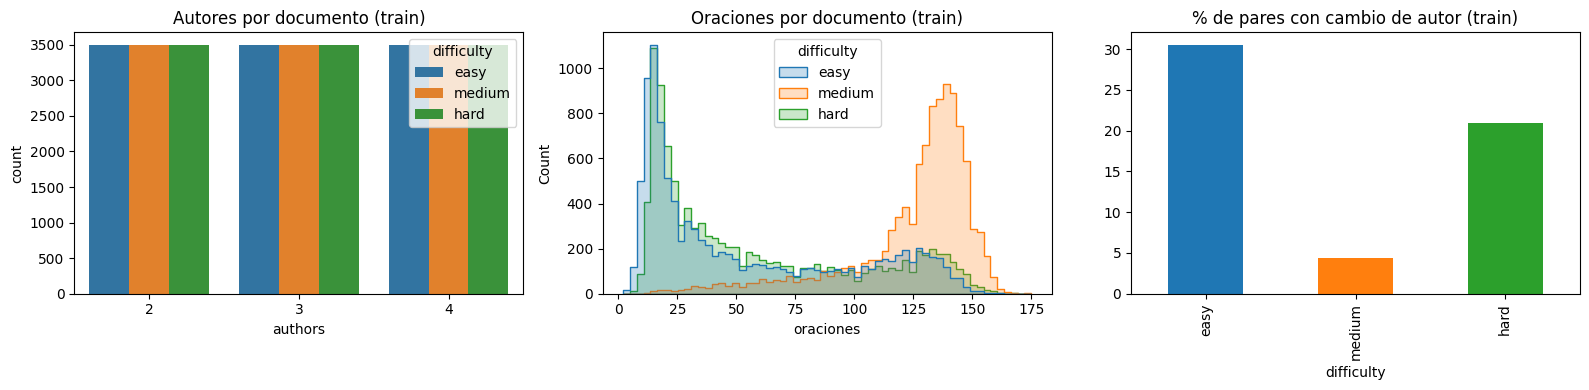

In [55]:
# 3.2 Distribuciones: autores por documento, oraciones por documento y % de cambios por dificultad
tr = truths[truths.split == "train"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=tr, x="authors", hue="difficulty", hue_order=DIFFICULTIES, ax=axes[0])
axes[0].set_title("Autores por documento (train)")
sns.histplot(data=tr, x=tr.n_pairs + 1, hue="difficulty", hue_order=DIFFICULTIES, bins=60, element="step", ax=axes[1])
axes[1].set_title("Oraciones por documento (train)")
axes[1].set_xlabel("oraciones")
sums = tr.groupby("difficulty")[["n_changes", "n_pairs"]].sum().reindex(DIFFICULTIES)
rate = 100 * sums.n_changes / sums.n_pairs
rate.plot.bar(ax=axes[2], color=sns.color_palette()[:3])
axes[2].set_title("% de pares con cambio de autor (train)")
plt.tight_layout()
plt.show()

             count  mean   std   min   50%    90%    95%    99%    max
difficulty                                                            
easy        5000.0  83.0  29.8  44.0  76.0  114.0  133.0  194.0  511.0
hard        5000.0  79.5  27.5  44.0  73.0  107.0  126.0  183.0  461.0
medium      5000.0  74.1  20.6  43.0  69.0   98.0  110.1  145.0  468.0

% de pares truncados con MAX_LEN=128: {'easy': 5.88, 'hard': 4.62, 'medium': 2.06}


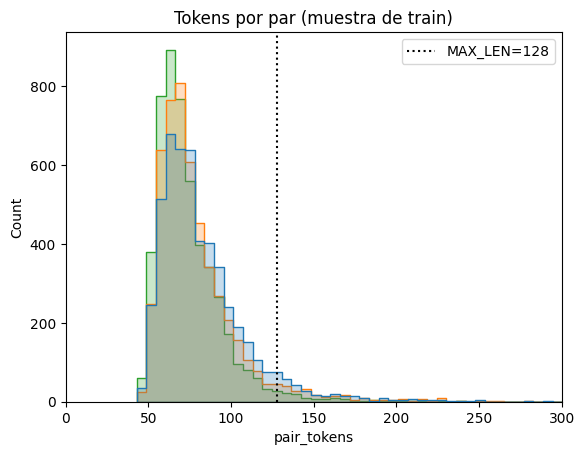

In [56]:
# 3.3 Longitud en tokens de RoBERTa: justifica MAX_LEN
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
sample = train_df.groupby("difficulty").sample(n=min(5000, len(train_df) // 3), random_state=SEED)
len_a = np.array([len(x) for x in tokenizer(sample.sent_a.tolist(), add_special_tokens=False)["input_ids"]])
len_b = np.array([len(x) for x in tokenizer(sample.sent_b.tolist(), add_special_tokens=False)["input_ids"]])
sample = sample.assign(pair_tokens=len_a + len_b + 4)  # <s> A </s></s> B </s>

print(sample.groupby("difficulty").pair_tokens.describe(percentiles=[.5, .9, .95, .99]).round(1))
print(f"\n% de pares truncados con MAX_LEN={MAX_LEN}:",
      (100 * sample.groupby("difficulty").pair_tokens.apply(lambda s: (s > MAX_LEN).mean())).round(2).to_dict())
sns.histplot(data=sample, x="pair_tokens", hue="difficulty", bins=80, element="step")
plt.axvline(MAX_LEN, color="k", linestyle=":", label=f"MAX_LEN={MAX_LEN}")
plt.xlim(0, 300)
plt.legend()
plt.title("Tokens por par (muestra de train)")
plt.show()

**Observaciones del EDA** (se completan tras ejecutar):
- **Desbalance**: el porcentaje de cambios varía mucho entre dificultades: ~30 % en *easy*, ~4 % en *medium* y ~21 % en *hard*. Por eso se usa una pérdida ponderada por clase y se ajusta el umbral de decisión en validación.
- **Longitud**: una oración mide ~34 tokens de mediana. Con `MAX_LEN = 128` se truncan muy pocos pares, y la truncación `longest_first` recorta la oración más larga, conservando el principio de ambas.
- **Tamaño**: train tiene ~2,4 M de pares. Una época completa en una GPU de 4 GB llevaría muchas horas, por eso se **submuestrean** 40k pares por dificultad. La validación y el test se evalúan **completos**.

## 4. Preprocesado: tokenización y batches eficientes

- **Entrada tipo *cross-encoder***: `<s> oración_i </s></s> oración_i+1 </s>`. La atención compara directamente los tokens de las dos oraciones, sin pasar antes por un vector resumen de cada una.
- **No se normaliza el texto** (ni minúsculas ni limpieza de puntuación). Las comillas tipográficas, las mayúsculas, los guiones y la puntuación son precisamente señales de estilo, y el BPE a nivel de byte de RoBERTa las conserva.
- **Padding dinámico y batches agrupados por longitud**: cada batch se rellena solo hasta su secuencia más larga, y las secuencias de longitud parecida van juntas. Se procesan muchos menos tokens de *padding* que rellenando siempre a `MAX_LEN`.

In [57]:
def encode(df, batch=20_000, difficulty_prefix=False):
    # Los tokens se guardan en un único array int32 + desplazamientos, no como listas de Python:
    # ~94 M de tokens ocuparían ~3-4 GB de RAM como listas de int y ~0,4 GB así.
    # difficulty_prefix=True (iteración 3): <s> dificultad </s></s> oración_i </s></s> oración_i+1 </s>
    flat, lengths = [], []
    sep2 = tokenizer.sep_token * 2
    for start in tqdm(range(0, len(df), batch), desc="Tokenizando", leave=False):
        chunk = df.iloc[start:start + batch]
        first = (chunk.difficulty + sep2 + chunk.sent_a) if difficulty_prefix else chunk.sent_a
        ids = tokenizer(first.tolist(), chunk.sent_b.tolist(), truncation="longest_first",
                        max_length=MAX_LEN, return_attention_mask=False)["input_ids"]
        lengths.append(np.fromiter((len(x) for x in ids), dtype=np.int32, count=len(ids)))
        flat.append(np.fromiter(itertools.chain.from_iterable(ids), dtype=np.int32))
    lengths = np.concatenate(lengths)
    offsets = np.concatenate([[0], np.cumsum(lengths, dtype=np.int64)])
    return {"tokens": np.concatenate(flat), "offsets": offsets, "length": lengths,
            "labels": df.label.to_numpy(dtype=np.int64)}


def length_grouped_batches(lengths, batch_size, shuffle, seed=SEED, chunk_factor=50):
    # shuffle=True: baraja, ordena por longitud dentro de bloques grandes y baraja el orden de los batches.
    # shuffle=False: ordena todo por longitud (inferencia: mínimo padding; el orden original se restaura después).
    if not shuffle:
        order = np.argsort(lengths, kind="stable")
        return [order[i:i + batch_size] for i in range(0, len(order), batch_size)]
    rng = np.random.default_rng(seed)
    order = rng.permutation(len(lengths))
    chunk = batch_size * chunk_factor
    batches = []
    for i in range(0, len(order), chunk):
        block = order[i:i + chunk]
        block = block[np.argsort(lengths[block], kind="stable")]
        batches += [block[j:j + batch_size] for j in range(0, len(block), batch_size)]
    rng.shuffle(batches)
    return batches


def pad_batch(enc, idx):
    lens = enc["length"][idx]
    ids = np.full((len(idx), int(lens.max())), tokenizer.pad_token_id, dtype=np.int64)
    mask = np.zeros_like(ids)
    for row, (i, n) in enumerate(zip(idx, lens)):
        start = enc["offsets"][i]
        ids[row, :n] = enc["tokens"][start:start + n]
        mask[row, :n] = 1
    return (torch.from_numpy(ids).pin_memory().to(device, non_blocking=True),
            torch.from_numpy(mask).pin_memory().to(device, non_blocking=True))


# Subconjunto de validación para monitorizar cada época (estratificado por dificultad)
monitor_df = (val_df.groupby("difficulty")
              .sample(n=min(N_VAL_MONITOR_PER_DIFF, val_df.difficulty.value_counts().min()), random_state=SEED)
              .reset_index(drop=True))

with Measure() as m:
    train_enc, monitor_enc = encode(train_df), encode(monitor_df)
    val_enc, test_enc = encode(val_df), encode(test_df)
print(f"Tokenización: {m.seconds:.0f} s")

batches = length_grouped_batches(train_enc["length"], 32, shuffle=True)
real = sum(len(b) * train_enc["length"][b].max() for b in batches)
print(f"Tokens procesados por época: con padding a MAX_LEN {len(train_df) * MAX_LEN:,} | "
      f"con padding dinámico agrupado {real:,} ({100 * real / (len(train_df) * MAX_LEN):.0f}%)")

Tokenización: 104 s
Tokens procesados por época: con padding a MAX_LEN 15,360,000 | con padding dinámico agrupado 9,395,392 (61%)


In [58]:
# Distribución de clases en lo que realmente se usa
pd.concat({name: df.groupby("difficulty").label.agg(pares="size", cambios="sum", pct=lambda s: 100 * s.mean())
           for name, df in [("train (muestra)", train_df), ("validation", val_df), ("test", test_df)]},
          axis=1).reindex(DIFFICULTIES).round(2)

train (muestra)                validation                   test  \
                     pares cambios    pct      pares cambios    pct   pares   
difficulty                                                                    
easy                 40000   12063  30.16     117435   35566  30.29  117569   
medium               40000    1802   4.50     278988   12225   4.38  279060   
hard                 40000    8302  20.76     127380   27065  21.25  127237   

                           
           cambios    pct  
difficulty                 
easy         35862  30.50  
medium       12093   4.33  
hard         26827  21.08

## 5. Métrica y baselines triviales

La métrica oficial de PAN es el **F1-macro** sobre los pares de cada dificultad, es decir, la media del F1 de la clase «cambio» y del F1 de la clase «sin cambio». Se implementa vectorizada con numpy para poder barrer umbrales rápidamente.

In [59]:
def macro_f1(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    f1s = []
    for c in (0, 1):
        tp = np.sum((y_pred == c) & (y_true == c))
        fp = np.sum((y_pred == c) & (y_true != c))
        fn = np.sum((y_pred != c) & (y_true == c))
        f1s.append(2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0)
    return float(np.mean(f1s))


def f1_by_difficulty(df, y_pred):
    y_pred = np.asarray(y_pred)
    scores = {f"F1 {d}": macro_f1(df.label.values[(df.difficulty == d).values], y_pred[(df.difficulty == d).values])
              for d in DIFFICULTIES}
    scores["F1 medio"] = float(np.mean(list(scores.values())))
    return scores


# Baseline 0: nunca hay cambio
record_score("Baseline: siempre «sin cambio»", f1_by_difficulty(test_df, np.zeros(len(test_df), dtype=int)), "—",
             "Cota inferior trivial")

# Baseline 1: aleatorio con la tasa de cambios de train de cada dificultad
rng = np.random.default_rng(SEED)
train_sums = truths[truths.split == "train"].groupby("difficulty")[["n_changes", "n_pairs"]].sum()
train_rate = train_sums.n_changes / train_sums.n_pairs
random_pred = (rng.random(len(test_df)) < test_df.difficulty.map(train_rate).values).astype(int)
record_score("Baseline: aleatorio estratificado", f1_by_difficulty(test_df, random_pred),
             "tasa de cambios de train", "Azar informado: F1 ≈ 0,5")
pd.DataFrame(SCOREBOARD).round(4)

,iteración,experimento,entrenamiento,F1 easy,F1 medium,F1 hard,F1 medio,conclusión
0,—,Baseline: siempre «sin cambio»,—,0.4100,0.4889,0.4411,0.4467,Cota inferior trivial
1,—,Baseline: aleatorio estratificado,tasa de cambios de train,0.4984,0.4993,0.5004,0.4994,"Azar informado: F1 ≈ 0,5"


## 6. Fine-tuning de RoBERTa-base como *cross-encoder* de pares

### Justificación del modelo
- **RoBERTa-base** (125 M de parámetros) es un *encoder* bidireccional preentrenado con más datos y durante más tiempo que BERT. En las ediciones anteriores de esta tarea en PAN, los participantes con mejores resultados usaron mayoritariamente *encoders* tipo RoBERTa/DeBERTa ajustados sobre pares de oraciones.
- **Tokenizador BPE a nivel de byte**: no tiene tokens `[UNK]` y conserva exactamente la puntuación, las comillas tipográficas, las mayúsculas y los espacios, que son señales estilométricas.
- **Cross-encoder**: el par se codifica conjuntamente, de modo que la atención cruzada compara directamente léxico, registro y puntuación de ambas oraciones. La representación de `<s>` alimenta un clasificador lineal de 2 clases.

### Optimización para la GPU (RTX 3050, 4 GB), según el cuaderno de optimización

| Técnica | Qué aporta aquí |
|---|---|
| **AMP en bfloat16** (`torch.autocast`) | Las multiplicaciones de matrices van en 16 bits sobre tensor cores: más velocidad y menos memoria de activaciones. Los pesos maestros siguen en float32. bf16 tiene el rango de float32, así que no necesita `GradScaler` (sí lo necesitaría en una GPU pre-Ampere con fp16). |
| **TF32** | Las operaciones float32 que quedan fuera de autocast también usan tensor cores. |
| **Atención SDPA** (`attn_implementation="sdpa"`) | Kernels fusionados de PyTorch (*memory-efficient* / *flash*): la atención no materializa la matriz N×N completa. |
| **AdamW fusionado** (`fused=True`) | Un solo kernel para actualizar todos los parámetros: menos lanzamientos de kernel por paso. |
| **Padding dinámico + agrupación por longitud** | Se procesan muchos menos tokens de relleno (ver sección 4). |
| **Batch físico elegido midiendo memoria + acumulación de gradiente** | Se busca el mayor batch que cabe con margen. En Windows, pasarse de la VRAM no da error: el driver usa memoria compartida y el entrenamiento se vuelve muchísimo más lento. Se acumulan gradientes hasta el batch efectivo de 32. |
| **Gradient checkpointing** (opcional) | Recalcula activaciones en el *backward*: cambia tiempo por memoria. Aquí no hace falta (ver la tabla de la frontera de batch). |

**¿Por qué no QLoRA?** La cuantización a 4 bits y LoRA están pensadas para modelos de miles de millones de parámetros. RoBERTa-base ocupa ~0,5 GB en float32, y el fine-tuning completo (pesos, gradientes y los dos momentos de Adam, ~2 GB) cabe en 4 GB. Además, en *encoders* pequeños el fine-tuning completo suele dar mejor resultado que los adaptadores. LoRA queda como posible experimento posterior.

In [60]:
def build_model(name_or_path=MODEL_NAME, gradient_checkpointing=GRADIENT_CHECKPOINTING, fp32_head=False):
    try:
        model = AutoModelForSequenceClassification.from_pretrained(name_or_path, num_labels=2, attn_implementation="sdpa")
    except (ValueError, ImportError):
        model = AutoModelForSequenceClassification.from_pretrained(name_or_path, num_labels=2)
    if gradient_checkpointing:
        model.gradient_checkpointing_enable()
    if fp32_head:
        # (Iteración 2) La cabeza de clasificación se ejecuta en float32 aunque el resto vaya en bf16:
        # logits con resolución completa -> probabilidades no cuantizadas. No cambia los pesos guardados.
        original = model.classifier.forward

        def forward_fp32(features, *args, **kwargs):
            with torch.autocast("cuda", enabled=False):
                return original(features.float(), *args, **kwargs)

        model.classifier.forward = forward_fp32
    return model.to(device)


def make_optimizer(model, lr=LEARNING_RATE):
    # Sin weight decay en sesgos y LayerNorm (parámetros 1-D)
    decay = [p for p in model.parameters() if p.requires_grad and p.ndim >= 2]
    no_decay = [p for p in model.parameters() if p.requires_grad and p.ndim < 2]
    return torch.optim.AdamW([{"params": decay, "weight_decay": WEIGHT_DECAY},
                              {"params": no_decay, "weight_decay": 0.0}], lr=lr, fused=True)


probe = build_model()
n_params = sum(p.numel() for p in probe.parameters())
print(f"{MODEL_NAME}: {n_params / 1e6:.1f} M parámetros | atención: {probe.config._attn_implementation} | "
      f"pesos fp32: {probe.get_memory_footprint() / 1024**3:.2f} GB")
release("probe")

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 336.49it/s]


roberta-base: 124.6 M parámetros | atención: sdpa | pesos fp32: 0.46 GB


### Frontera del tamaño de batch

Se prueba cada tamaño de batch con el peor caso (todas las secuencias de longitud `MAX_LEN`) durante dos pasos de entrenamiento completos. El segundo paso es el que reserva los estados de Adam. Se elige el mayor batch cuya memoria reservada quede por debajo del `MEMORY_BUDGET_FRACTION` de la VRAM.

In [61]:
def try_batch(batch_size, seq_len=MAX_LEN):
    model = optimizer = None
    try:
        gc.collect()
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        model = build_model()
        model.train()
        optimizer = make_optimizer(model)
        ids = torch.randint(5, tokenizer.vocab_size - 1, (batch_size, seq_len), device=device)
        mask = torch.ones_like(ids)
        labels = torch.randint(0, 2, (batch_size,), device=device)
        start = time.perf_counter()
        for _ in range(2):
            with torch.autocast("cuda", dtype=AMP_DTYPE):
                loss = model(input_ids=ids, attention_mask=mask, labels=labels).loss
            loss.backward()
            optimizer.step()
            optimizer.zero_grad(set_to_none=True)
        torch.cuda.synchronize()
        seconds = (time.perf_counter() - start) / 2
        peak = torch.cuda.max_memory_reserved() / 1024**3
        return {"batch": batch_size, "cabe": peak < MEMORY_BUDGET_FRACTION * GPU_MEMORY_GB,
                "memoria reservada pico (GB)": round(peak, 2), "s/paso (peor caso)": round(seconds, 3)}
    except torch.OutOfMemoryError:
        return {"batch": batch_size, "cabe": False, "memoria reservada pico (GB)": float("nan"), "s/paso (peor caso)": float("nan")}
    finally:
        del model, optimizer
        gc.collect()
        torch.cuda.empty_cache()


frontier = []
for bs in [b for b in (64, 32, 16, 8, 4) if b <= EFFECTIVE_BATCH_SIZE]:
    frontier.append(try_batch(bs))
    if frontier[-1]["cabe"]:
        break
frontier = pd.DataFrame(frontier)
fitting = frontier[frontier.cabe]
PHYSICAL_BATCH_SIZE = int(fitting.batch.max()) if len(fitting) else 4
GRAD_ACCUM_STEPS = max(1, EFFECTIVE_BATCH_SIZE // PHYSICAL_BATCH_SIZE)
print(f"Batch físico = {PHYSICAL_BATCH_SIZE} | acumulación = {GRAD_ACCUM_STEPS} | "
      f"batch efectivo = {PHYSICAL_BATCH_SIZE * GRAD_ACCUM_STEPS}")
frontier

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 570.21it/s]


Batch físico = 32 | acumulación = 1 | batch efectivo = 32


,batch,cabe,memoria reservada pico (GB),s/paso (peor caso)
0,32,True,3.38,0.322


In [62]:
@torch.inference_mode()
def predict_proba(model, enc, batch_size=EVAL_BATCH_SIZE, desc="Inferencia"):
    # Probabilidad de la clase 1 (cambio de autor) para cada par, en el orden original
    model.eval()
    probs = np.empty(len(enc["length"]), dtype=np.float32)
    for idx in tqdm(length_grouped_batches(enc["length"], batch_size, shuffle=False), desc=desc, leave=False):
        ids, mask = pad_batch(enc, idx)
        with torch.autocast("cuda", dtype=AMP_DTYPE):
            logits = model(input_ids=ids, attention_mask=mask).logits
        probs[idx] = torch.softmax(logits.float(), dim=-1)[:, 1].cpu().numpy()
    return probs


def class_weights_from(labels):
    # Pesos inversamente proporcionales a la frecuencia (normalizados a media 1)
    counts = np.bincount(labels, minlength=2).astype(np.float64)
    w = counts.sum() / (2 * counts)
    return torch.tensor(w, dtype=torch.float32, device=device)


def train_model(model, train_enc, monitor_df, monitor_enc, epochs=EPOCHS, model_dir=MODEL_DIR,
                use_class_weights=USE_CLASS_WEIGHTS, eval_every=None):
    # eval_every=None: se evalúa y guarda el mejor checkpoint al final de cada época (iteración 1).
    # eval_every=N: además cada N pasos de optimizador (iteraciones 2 y 3, que entrenan 1 sola época).
    seed_everything()
    optimizer = make_optimizer(model)
    n_batches = math.ceil(len(train_enc["length"]) / PHYSICAL_BATCH_SIZE)
    total_updates = epochs * math.ceil(n_batches / GRAD_ACCUM_STEPS)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_updates), total_updates)
    scaler = torch.amp.GradScaler("cuda", enabled=AMP_DTYPE == torch.float16)
    weights = class_weights_from(train_enc["labels"]) if use_class_weights else None
    loss_fn = torch.nn.CrossEntropyLoss(weight=weights)
    labels_all = torch.from_numpy(train_enc["labels"])
    print("Pesos de clase:", None if weights is None else weights.tolist())

    history = {"update": [], "loss": [], "lr": [], "epoch": [], "monitor": []}
    state = {"best": -1.0, "last_eval": None}

    def checkpoint(epoch, update):
        # Batch de evaluación reducido y liberación de la caché de memoria tras evaluar: con entradas largas
        # (it. 4), la memoria extra que reserva la evaluación se sumaba a la del entrenamiento y Windows
        # desbordaba a memoria compartida (RAM del sistema), multiplicando por 3-4 el tiempo por paso.
        probs = predict_proba(model, monitor_enc, batch_size=PHYSICAL_BATCH_SIZE * 2, desc="Monitor validación")
        gc.collect()
        torch.cuda.empty_cache()
        model.train()
        scores = f1_by_difficulty(monitor_df, (probs >= 0.5).astype(int))
        history["monitor"].append({"epoch": epoch, "update": update, **scores})
        state["last_eval"] = update
        print(f"Época {epoch} | paso {update}: " + " | ".join(f"{k} {v:.4f}" for k, v in scores.items()))
        if scores["F1 medio"] > state["best"]:
            state["best"] = scores["F1 medio"]
            model.save_pretrained(model_dir)
            tokenizer.save_pretrained(model_dir)
            print(f"  -> mejor checkpoint guardado en {model_dir}")

    update, running, n_running = 0, torch.zeros((), device=device), 0
    for epoch in range(epochs):
        model.train()
        batches = length_grouped_batches(train_enc["length"], PHYSICAL_BATCH_SIZE, shuffle=True, seed=SEED + epoch)
        optimizer.zero_grad(set_to_none=True)
        bar = tqdm(batches, desc=f"Época {epoch + 1}/{epochs}")
        for i, idx in enumerate(bar):
            ids, mask = pad_batch(train_enc, idx)
            labels = labels_all[idx].to(device, non_blocking=True)
            with torch.autocast("cuda", dtype=AMP_DTYPE):
                logits = model(input_ids=ids, attention_mask=mask).logits
            loss = loss_fn(logits.float(), labels) / GRAD_ACCUM_STEPS
            scaler.scale(loss).backward()
            running += loss.detach() * GRAD_ACCUM_STEPS
            n_running += 1
            if (i + 1) % GRAD_ACCUM_STEPS == 0 or i + 1 == len(batches):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
                scheduler.step()
                update += 1
                if update % LOG_EVERY == 0:  # .item() sincroniza CPU-GPU: solo cada LOG_EVERY pasos
                    avg = (running / n_running).item()
                    history["update"].append(update); history["loss"].append(avg)
                    history["lr"].append(scheduler.get_last_lr()[0]); history["epoch"].append(epoch + 1)
                    bar.set_postfix(loss=f"{avg:.4f}")
                    running.zero_(); n_running = 0
                if eval_every and update % eval_every == 0:
                    checkpoint(epoch + 1, update)

        if state["last_eval"] != update:  # evaluación de fin de época (si no acaba de hacerse)
            checkpoint(epoch + 1, update)
    return history


def run_training(model_dir, train_enc, monitor_df, monitor_enc, epochs, use_class_weights, eval_every, fp32_head):
    # Entrena y guarda el historial, o lo carga si el modelo ya existe y RETRAIN=False
    history_path = model_dir / "history.json"
    if RETRAIN or not (model_dir / "config.json").exists():
        model_dir.mkdir(parents=True, exist_ok=True)
        model = build_model(fp32_head=fp32_head)
        with Measure() as m:
            history = train_model(model, train_enc, monitor_df, monitor_enc, epochs=epochs, model_dir=model_dir,
                                  use_class_weights=use_class_weights, eval_every=eval_every)
        history["train_seconds"], history["train_peak_gb"] = m.seconds, m.peak_gb
        history_path.write_text(json.dumps(history, indent=1))
        del model
        gc.collect()
        torch.cuda.empty_cache()
    else:
        history = json.loads(history_path.read_text())
        print(f"Modelo ya entrenado en {model_dir}: se carga de disco (pon RETRAIN=True para reentrenar)")
    print(f"Entrenamiento: {history['train_seconds'] / 60:.1f} min | memoria pico {history['train_peak_gb']:.2f} GB")
    return history


def cached_probs(name, model_dir, enc, fp32_head=False, desc="Inferencia"):
    # Probabilidades guardadas en results/<name>.npy; se recalculan solo si el modelo es más reciente.
    # Así re-ejecutar el notebook no repite la inferencia (~30 min por partición completa).
    path, cost_path = RESULTS_DIR / f"{name}.npy", RESULTS_DIR / f"{name}.json"
    weights = model_dir / "model.safetensors"
    if path.exists() and path.stat().st_mtime > weights.stat().st_mtime:
        cost = json.loads(cost_path.read_text()) if cost_path.exists() else {}
        return np.load(path), cost
    model = build_model(model_dir, fp32_head=fp32_head)
    with Measure() as m:
        probs = predict_proba(model, enc, desc=desc)
    del model
    gc.collect()
    torch.cuda.empty_cache()
    cost = {"segundos": round(m.seconds), "memoria pico (GB)": round(m.peak_gb, 2),
            "pares/s": round(len(probs) / m.seconds, 1)}
    np.save(path, probs)
    cost_path.write_text(json.dumps(cost))
    return probs, cost

In [63]:
# Iteración 1: entrenamiento (o carga del checkpoint si ya existe y RETRAIN=False)
history = run_training(MODEL_DIR, train_enc, monitor_df, monitor_enc, epochs=EPOCHS,
                       use_class_weights=USE_CLASS_WEIGHTS, eval_every=None, fp32_head=False)
record_cost("It. 1 · fine-tuning", **{
    "segundos": round(history["train_seconds"]), "memoria pico (GB)": round(history["train_peak_gb"], 2),
    "pares de train": len(train_df), "épocas": EPOCHS, "batch físico": PHYSICAL_BATCH_SIZE,
    "pares/s": round(EPOCHS * len(train_df) / history["train_seconds"], 1)})

Modelo ya entrenado en models\roberta-base-pairs: se carga de disco (pon RETRAIN=True para reentrenar)
Entrenamiento: 32.4 min | memoria pico 3.18 GB


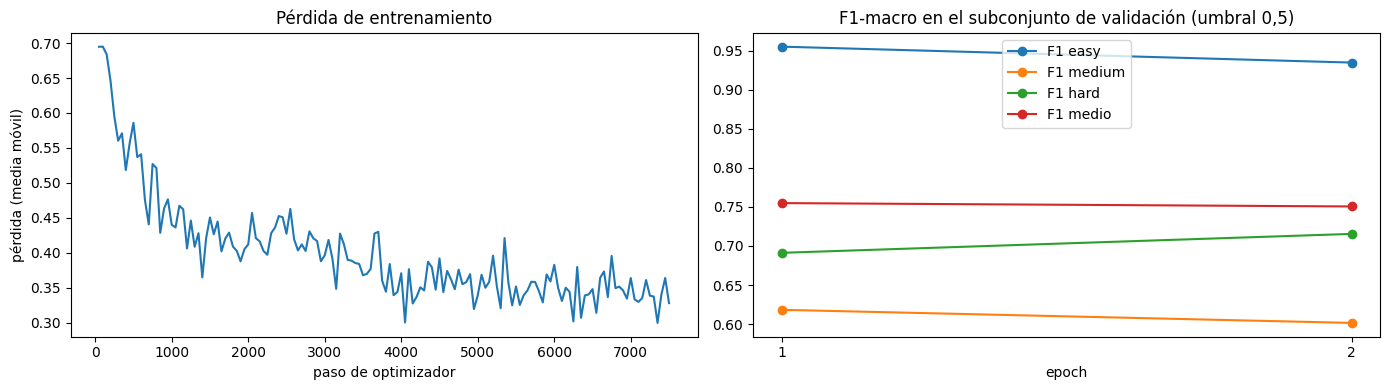

,F1 easy,F1 medium,F1 hard,F1 medio
epoch,,,,
1,0.9553,0.6182,0.6912,0.7549
2,0.9349,0.6015,0.7155,0.7506


In [64]:
# Curvas de entrenamiento
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(history["update"], history["loss"])
axes[0].set_xlabel("paso de optimizador")
axes[0].set_ylabel("pérdida (media móvil)")
axes[0].set_title("Pérdida de entrenamiento")
mon = pd.DataFrame(history["monitor"]).set_index("epoch")[["F1 easy", "F1 medium", "F1 hard", "F1 medio"]]
mon.plot(marker="o", ax=axes[1])
axes[1].set_title("F1-macro en el subconjunto de validación (umbral 0,5)")
axes[1].set_xticks(mon.index)
plt.tight_layout()
plt.show()
mon.round(4)

### Inferencia sobre validación y test completos

Se carga el **mejor checkpoint**, es decir, el de mayor F1 medio en el subconjunto de monitorización, y se calculan las probabilidades de todos los pares. Las probabilidades se guardan en `results/`: si el notebook se vuelve a ejecutar y el modelo no ha cambiado, se reutilizan en lugar de repetir la inferencia.

In [65]:
val_probs, cost = cached_probs("roberta_val_probs", MODEL_DIR, val_enc, desc="Validación")
test_probs, _ = cached_probs("roberta_test_probs", MODEL_DIR, test_enc, desc="Test")
if cost:
    record_cost("It. 1 · inferencia validación completa", **cost)
    print(f"Inferencia validación: {cost['segundos']} s ({cost['pares/s']} pares/s)")

Inferencia validación: 1765 s (296.8 pares/s)


### Ajuste del umbral de decisión en validación

Con clases desbalanceadas, el umbral 0,5 no tiene por qué maximizar el F1-macro. El umbral se elige **solo con validación** y se aplica después a test, de dos maneras:
- **Global**: un único umbral que maximiza el F1 medio de las tres dificultades.
- **Por dificultad**: un umbral para cada nivel. Es legítimo porque en PAN cada dificultad es un conjunto de datos separado y conocido.

Umbral global: 0.68 | por dificultad: {'easy': 0.94, 'medium': 0.85, 'hard': 0.32}


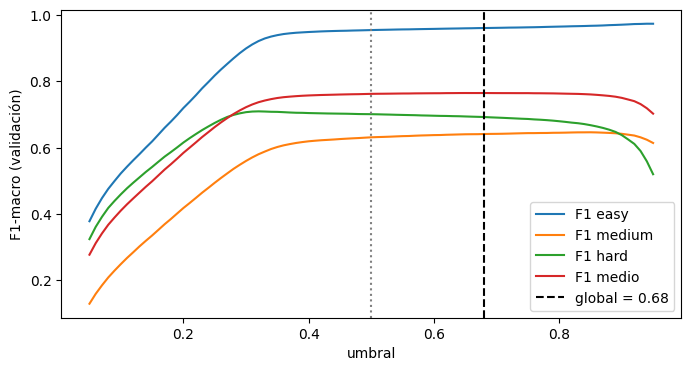

In [66]:
thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
sweep = pd.DataFrame([{"umbral": t, **f1_by_difficulty(val_df, (val_probs >= t).astype(int))} for t in thresholds])
best_global = float(sweep.loc[sweep["F1 medio"].idxmax(), "umbral"])
best_per_diff = {d: float(sweep.loc[sweep[f"F1 {d}"].idxmax(), "umbral"]) for d in DIFFICULTIES}
print("Umbral global:", best_global, "| por dificultad:", best_per_diff)

sweep.set_index("umbral").plot(figsize=(8, 4))
plt.axvline(0.5, color="grey", linestyle=":")
plt.axvline(best_global, color="k", linestyle="--", label=f"global = {best_global}")
plt.ylabel("F1-macro (validación)")
plt.legend()
plt.show()

In [67]:
# Evaluación final en TEST
train_info = f"{N_TRAIN_PAIRS_PER_DIFF:,} pares/dif. (natural), {EPOCHS} épocas, pesos de clase"
per_diff_thr = test_df.difficulty.map(best_per_diff).values
variants = {
    "RoBERTa-base pares (umbral 0,5)": (test_probs >= 0.5,
        "Easy casi resuelto; en medium y hard se pierde más de la mitad de los cambios (FN)"),
    f"RoBERTa-base pares (umbral global {best_global})": (test_probs >= best_global,
        "Un único umbral no sirve: mejora easy/medium y empeora hard"),
    "RoBERTa-base pares (umbral por dificultad)": (test_probs >= per_diff_thr,
        "Mejor de la it. 1; umbrales muy distintos = modelo no calibrado por dificultad"),
}
for name, (pred, conclusion) in variants.items():
    record_score(name, f1_by_difficulty(test_df, pred.astype(int)), train_info, conclusion, iteration="1")

test_pred = (test_probs >= per_diff_thr).astype(int)
PREDS = {"It. 1": (test_probs, test_pred)}  # predicciones de test de cada iteración, para compararlas al final
pd.DataFrame(SCOREBOARD).round(4)

,iteración,experimento,entrenamiento,F1 easy,F1 medium,F1 hard,F1 medio,conclusión
0,—,Baseline: siempre «sin cambio»,—,0.4100,0.4889,0.4411,0.4467,Cota inferior trivial
1,—,Baseline: aleatorio estratificado,tasa de cambios de train,0.4984,0.4993,0.5004,0.4994,"Azar informado: F1 ≈ 0,5"
2,1,"RoBERTa-base pares (umbral 0,5)","40,000 pares/dif. (natural), 2 épocas, pesos de clase",0.9553,0.6270,0.7014,0.7612,Easy casi resuelto; en medium y hard se pierde más de la mitad de los cambios (FN)
3,1,RoBERTa-base pares (umbral global 0.68),"40,000 pares/dif. (natural), 2 épocas, pesos de clase",0.9609,0.6384,0.6921,0.7638,Un único umbral no sirve: mejora easy/medium y empeora hard
4,1,RoBERTa-base pares (umbral por dificultad),"40,000 pares/dif. (natural), 2 épocas, pesos de clase",0.9745,0.6454,0.7117,0.7772,Mejor de la it. 1; umbrales muy distintos = modelo no calibrado por dificultad


===== easy (umbral 0.94) =====
              precision    recall  f1-score   support

  sin cambio     0.9755    0.9943    0.9848     81707
      cambio     0.9864    0.9431    0.9643     35862

    accuracy                         0.9787    117569
   macro avg     0.9810    0.9687    0.9745    117569
weighted avg     0.9788    0.9787    0.9785    117569

===== medium (umbral 0.85) =====
              precision    recall  f1-score   support

  sin cambio     0.9699    0.9657    0.9678    266967
      cambio     0.3088    0.3387    0.3230     12093

    accuracy                         0.9385    279060
   macro avg     0.6393    0.6522    0.6454    279060
weighted avg     0.9413    0.9385    0.9398    279060

===== hard (umbral 0.32) =====
              precision    recall  f1-score   support

  sin cambio     0.8710    0.9035    0.8869    100410
      cambio     0.5800    0.4990    0.5364     26827

    accuracy                         0.8182    127237
   macro avg     0.7255    0.7012

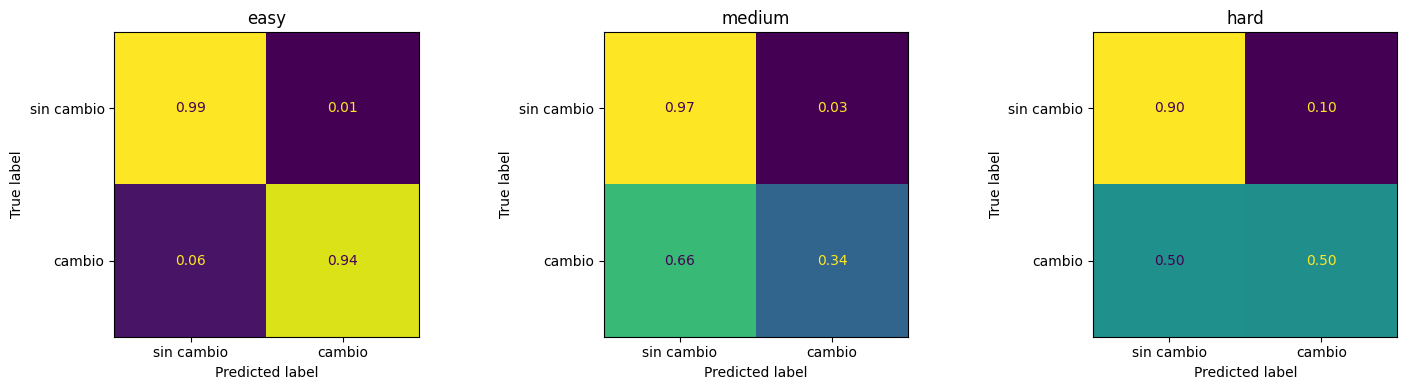

In [68]:
# Informe por clase y matrices de confusión (variante con umbral por dificultad)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, d in zip(axes, DIFFICULTIES):
    mask = (test_df.difficulty == d).values
    print(f"===== {d} (umbral {best_per_diff[d]}) =====")
    print(classification_report(test_df.label.values[mask], test_pred[mask], target_names=["sin cambio", "cambio"], digits=4))
    ConfusionMatrixDisplay(confusion_matrix(test_df.label.values[mask], test_pred[mask], normalize="true"),
                           display_labels=["sin cambio", "cambio"]).plot(ax=ax, colorbar=False, values_format=".2f")
    ax.set_title(d)
plt.tight_layout()
plt.show()

In [69]:
# Análisis de errores: F1-macro en test según el número de autores del documento
by_authors = (test_df.assign(pred=test_pred)
              .groupby(["difficulty", "authors"])
              .apply(lambda g: pd.Series({"pares": len(g), "% cambios": 100 * g.label.mean(),
                                          "F1-macro": macro_f1(g.label, g.pred)}), include_groups=False)
              .round(3))
by_authors.unstack(0)["F1-macro"]

difficulty,easy,hard,medium
authors,,,
2,0.979,0.671,0.590
3,0.977,0.717,0.646
4,0.972,0.712,0.669


In [70]:
# Ejemplos de errores en 'hard' (falsos positivos con mayor probabilidad y falsos negativos con menor)
errors = test_df.assign(prob=test_probs, pred=test_pred)
errors = errors[(errors.difficulty == "hard") & (errors.label != errors.pred)]
pd.concat([errors[errors.label == 0].nlargest(4, "prob"), errors[errors.label == 1].nsmallest(4, "prob")])[
    ["label", "prob", "sent_a", "sent_b"]]

,label,prob,sent_a,sent_b
397637,0,0.999103,"He had decided to spend the night in the giants bed, only because said giant wouldn’t let him up when he’d wanted to...",He could feel the tears run down his cheek as his eye continued to water from the obstruction still in it.
409188,0,0.999103,"They have risked themselves for years, lost so much to a merciless world, endlessly teetering between life and death...","“What’s that for?” She pushes back tangled hair away from his face, and her fingernails scrape against his ear pleas..."
440767,0,0.999103,"Carol asked him one morning, when he once again came strolling into her office at Ferris Airfields straight from his...",And it was really fucking nice to be babied and petted and spoiled in the rare moments he had to himself.
440868,0,0.999103,"They are not children, anymore, and yet, inexplicably, that is all that they ever could possibly be.","He doesn’t tell them about how the world had become a creaky rollercoaster, a broken carousel that had distorted and..."
476700,1,0.029760,"Mirage pinned Hound by the shoulder, snaking his other arm down to stroke over Hound’s pressurised spike; then he sl...","Hound’s first experimental thrust had Mirage gasping as Hound’s spike slid over his wet valve, the ridges of it rubb..."
484823,1,0.029760,"Just tell them, right?” “How?” Connor asks, and the word sounds almost desperate as his LED flashes yellow, reflec...","“Aw, damn,” Connor says, LED going yellow at the swear word as it does every time, but the smile doesn’t go away, an..."
520693,1,0.030215,"“I have to check on something in the kitchen,” Oliver murmured, before turning around and heading through the double...",“Are you seeing what I'm seeing?” Felicity asked quietly to her best friend as they stood at the doorway to the kitc...
404962,1,0.030676,"Doyoung stretched an arm out, just managing to grab the bottle that had been left on the nightstand from the night b...",Jaehyun pulled the plastic bottle of lube out and set it atop the nightstand before turning to the bed.


## 7. Diagnóstico de la iteración 1

Antes de cambiar nada se analizan los errores del modelo de la iteración 1 **en validación** (nunca en test, para no ajustar las decisiones al conjunto de evaluación final).

In [71]:
# Errores por dificultad en VALIDACIÓN con el umbral 0,5
diag = []
for d in DIFFICULTIES:
    m = (val_df.difficulty == d).values
    y, p = val_df.label.values[m], val_probs[m]
    fn, fp = int(((p < 0.5) & (y == 1)).sum()), int(((p >= 0.5) & (y == 0)).sum())
    diag.append({"dificultad": d,
                 "cambios en la muestra de train": int(train_df.label[train_df.difficulty == d].sum()),
                 "cambios en validación": int(y.sum()), "FN @0,5": fn, "% cambios perdidos": 100 * fn / y.sum(),
                 "FP @0,5": fp, "prob. media | cambio": p[y == 1].mean(), "prob. media | sin cambio": p[y == 0].mean(),
                 "umbral óptimo": best_per_diff[d], "valores distintos de prob.": len(np.unique(p))})
pd.DataFrame(diag).set_index("dificultad").round(3)

,cambios en la muestra de train,cambios en validación,"FN @0,5",% cambios perdidos,"FP @0,5",prob. media | cambio,prob. media | sin cambio,umbral óptimo,valores distintos de prob.
dificultad,,,,,,,,,
easy,12063,35566,811,2.280,3740,0.975,0.192,0.94,3181
medium,1802,12225,6678,54.626,18007,0.542,0.223,0.85,5072
hard,8302,27065,16445,60.761,4648,0.489,0.191,0.32,3597


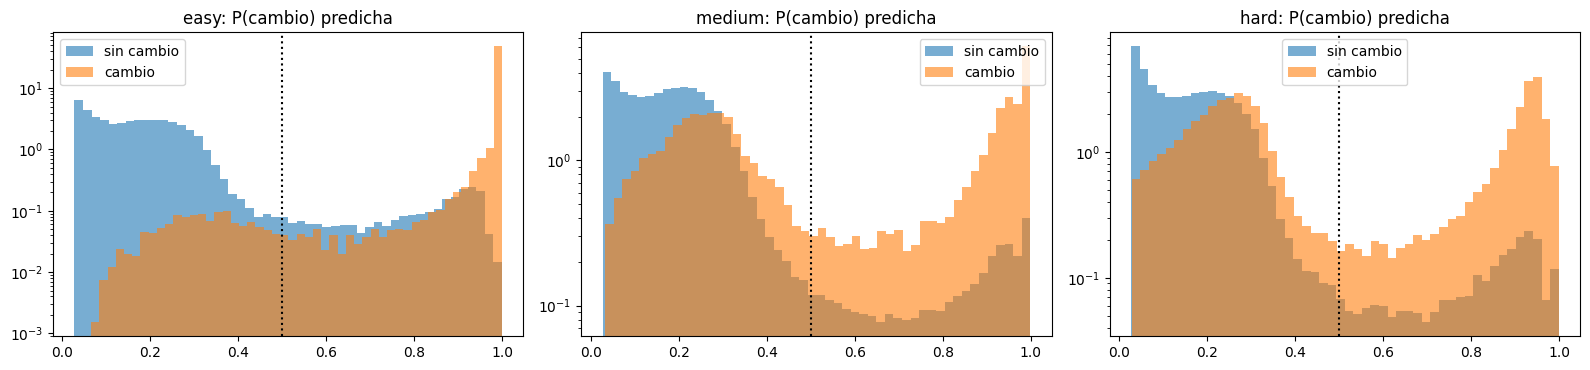

F1 en el subconjunto de monitorización por época (iteración 1):


,F1 easy,F1 medium,F1 hard,F1 medio
epoch,,,,
1,0.9553,0.6182,0.6912,0.7549
2,0.9349,0.6015,0.7155,0.7506


In [72]:
# Distribución de la probabilidad predicha según la etiqueta real
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, d in zip(axes, DIFFICULTIES):
    m = (val_df.difficulty == d).values
    for label, name in [(0, "sin cambio"), (1, "cambio")]:
        ax.hist(val_probs[m][val_df.label.values[m] == label], bins=50, alpha=0.6, density=True, label=name)
    ax.axvline(0.5, color="k", linestyle=":")
    ax.set_title(f"{d}: P(cambio) predicha")
    ax.set_yscale("log")
    ax.legend()
plt.tight_layout()
plt.show()

mon1 = pd.DataFrame(history["monitor"]).set_index("epoch")[["F1 easy", "F1 medium", "F1 hard", "F1 medio"]]
print("F1 en el subconjunto de monitorización por época (iteración 1):")
mon1.round(4)

### Conclusiones del diagnóstico

Las cifras corresponden a la ejecución de la iteración 1 (validación, umbral 0,5):

1. **Muchos falsos negativos en *medium* y *hard*.** Se pierde el **55 %** de los cambios en *medium* (6.678 de 12.225) y el **61 %** en *hard* (16.445 de 27.065), frente al 2 % en *easy*. La probabilidad media que el modelo asigna a un cambio real es 0,54 en *medium* y 0,49 en *hard*, frente a 0,98 en *easy*: en *medium* y *hard* el modelo **no separa bien** las clases.
2. **Muy pocos ejemplos de cambio.** El muestreo uniforme respeta la distribución natural, así que la muestra de *medium* solo tenía **1.802 cambios** (4,5 %), aunque en todo el train hay 56.631. Con tan pocos positivos el modelo apenas aprende cómo es un cambio de estilo.
3. **Calibración distinta por dificultad.** Los umbrales óptimos son 0,94 / 0,85 / 0,32. En *medium* hay incluso **más falsos positivos (18.007) que cambios reales**, mientras que en *hard* faltan positivos. El modelo no sabe de qué dificultad es cada par y aplica la misma regla a las tres. Además, los pesos de clase (×2,5 para «cambio») se calcularon sobre la mezcla de las tres dificultades, cuyas tasas de cambio son muy distintas (30 %, 4 %, 21 %).
4. **La segunda época empeora.** El F1 medio de monitorización baja de 0,7549 a 0,7506, y *easy* y *medium* bajan. La segunda pasada repite **los mismos** 120.000 pares, cuando el train tiene 2,4 millones de pares distintos: es más útil ver datos nuevos que repetir.
5. **Probabilidades cuantizadas.** Solo hay entre 3.000 y 5.000 valores distintos de probabilidad para 117.000–279.000 pares, y en los errores aparecen pares distintos con exactamente la misma probabilidad (0,999103). Se debe a que los logits se calculan en bfloat16, que tiene solo 8 bits de mantisa. Esto reduce la resolución con la que se puede ajustar el umbral.
6. **Coste de evaluación.** La inferencia sobre la validación completa (524.000 pares) tarda ~29 minutos.

## 8. Iteración 2: más ejemplos de cambio, más datos distintos y cabeza en fp32

### Cambios respecto a la iteración 1

| Aspecto | Iteración 1 | Iteración 2 | Por qué (punto del diagnóstico) |
|---|---|---|---|
| Muestreo de train | 40.000 pares/dificultad, distribución natural (*medium*: 1.802 cambios) | **80.000 pares/dificultad con un 35 % de cambios** (28.000 cambios por dificultad) | (1) y (2): 15 veces más cambios en *medium* y 3,4 veces más en *hard*. |
| Pesos de clase | Sí (×2,5 para «cambio») | **No** | La muestra ya está rebalanceada; usar también pesos sobrecompensaría. El desajuste con la tasa real se corrige con el umbral en validación. |
| Épocas | 2 × 120.000 pares | **1 × 240.000 pares distintos** | (4): mismo coste de cómputo (240.000 pasadas) pero sin repetir ningún par. |
| Selección del checkpoint | Al final de cada época (2 puntos) | **Cada 1.500 pasos** (5 puntos) | Con una sola época hacen falta evaluaciones intermedias para quedarse con el mejor punto. |
| Cabeza de clasificación | bf16 (dentro de autocast) | **float32** (autocast desactivado solo en la cabeza) | (5): probabilidades con resolución completa. Coste despreciable: es una capa de 768×768 más una de 768×2. |
| Validación para el umbral | Completa (524.000 pares, ~29 min) | **40.000 pares/dificultad**, disjuntos del subconjunto de monitorización | (6): el umbral es un único parámetro por dificultad, y 40.000 pares (~1.750 cambios en *medium*) bastan. **El test sigue siendo completo.** |

Lo que **no** cambia: modelo, `MAX_LEN`, tasa de aprendizaje, *warmup*, batch efectivo y todas las optimizaciones de GPU. Se cambian varias cosas a la vez porque todas atacan el mismo problema (falta de positivos y mala calibración), y con ~1 hora por experimento en esta GPU no es posible aislar cada una. La iteración 3 sí cambia **una única cosa**.

In [73]:
# Configuración de la iteración 2
V2_DIR = MODEL_DIR.parent / "roberta-base-pairs-v2"
V2_PAIRS_PER_DIFF = 80_000
V2_POS_FRACTION = 0.35
V2_EPOCHS = 1
V2_EVAL_EVERY = 1_500                 # pasos de optimizador entre evaluaciones de monitorización
N_VAL_THRESHOLD_PER_DIFF = 40_000     # pares de validación por dificultad para ajustar el umbral
if SMOKE_TEST:
    V2_PAIRS_PER_DIFF, V2_EVAL_EVERY, N_VAL_THRESHOLD_PER_DIFF = 600, 20, 300


def sample_train_keep_balanced(truths_train, n_pairs, pos_fraction, seed):
    # Muestreo estratificado: pos_fraction de los pares son cambios, el resto no-cambios
    rng = np.random.default_rng(seed)
    flat_labels = np.concatenate(truths_train.changes.values)
    offsets = np.concatenate([[0], np.cumsum(truths_train.n_pairs.values)])
    pos, neg = np.flatnonzero(flat_labels == 1), np.flatnonzero(flat_labels == 0)
    n_pos = min(int(round(n_pairs * pos_fraction)), len(pos))
    chosen = np.sort(np.concatenate([rng.choice(pos, n_pos, replace=False),
                                     rng.choice(neg, min(n_pairs - n_pos, len(neg)), replace=False)]))
    owner = np.searchsorted(offsets, chosen, side="right") - 1
    keep = {}
    for o, flat in zip(owner, chosen):
        keep.setdefault(truths_train.problem_id.values[o], []).append(flat - offsets[o])
    return truths_train[truths_train.problem_id.isin(keep)], keep


def load_train_pairs_balanced(n_per_diff, pos_fraction, seed):
    parts = []
    for d in DIFFICULTIES:
        t = truths[(truths.difficulty == d) & (truths.split == "train")]
        t, keep = sample_train_keep_balanced(t, n_per_diff, pos_fraction, seed)
        parts.append(build_pairs(reader, t, keep, desc=f"{d}/train"))
    return pd.concat(parts, ignore_index=True)


train_v2_df = cached(f"train_pairs_v2_{V2_PAIRS_PER_DIFF}_pos{int(100 * V2_POS_FRACTION)}",
                     lambda: load_train_pairs_balanced(V2_PAIRS_PER_DIFF, V2_POS_FRACTION, SEED))

# Subconjunto de validación para el umbral, disjunto del de monitorización (que elige el checkpoint)
key_cols = ["difficulty", "problem_id", "idx"]
in_monitor = pd.MultiIndex.from_frame(val_df[key_cols]).isin(pd.MultiIndex.from_frame(monitor_df[key_cols]))
thr_pool = val_df[~in_monitor]
thr_df = (thr_pool.groupby("difficulty")
          .sample(n=min(N_VAL_THRESHOLD_PER_DIFF, thr_pool.difficulty.value_counts().min()), random_state=SEED + 1)
          .reset_index(drop=True))

pd.concat({"train it. 1": train_df.groupby("difficulty").label.agg(pares="size", cambios="sum"),
           "train it. 2": train_v2_df.groupby("difficulty").label.agg(pares="size", cambios="sum"),
           "validación para umbral": thr_df.groupby("difficulty").label.agg(pares="size", cambios="sum")},
          axis=1).reindex(DIFFICULTIES)

train it. 1         train it. 2         validación para umbral  \
                 pares cambios       pares cambios                  pares   
difficulty                                                                  
easy             40000   12063       80000   28000                  40000   
medium           40000    1802       80000   28000                  40000   
hard             40000    8302       80000   28000                  40000   

                    
           cambios  
difficulty          
easy         12212  
medium        1779  
hard          8544

In [74]:
# Liberamos lo que ya no hace falta de la iteración 1 (la RAM es justa: 16 GB)
release("train_enc", "val_enc")
with Measure() as m:
    train_v2_enc, thr_enc = encode(train_v2_df), encode(thr_df)
print(f"Tokenización: {m.seconds:.0f} s")

history_v2 = run_training(V2_DIR, train_v2_enc, monitor_df, monitor_enc, epochs=V2_EPOCHS,
                          use_class_weights=False, eval_every=V2_EVAL_EVERY, fp32_head=True)
record_cost("It. 2 · fine-tuning", **{
    "segundos": round(history_v2["train_seconds"]), "memoria pico (GB)": round(history_v2["train_peak_gb"], 2),
    "pares de train": len(train_v2_df), "épocas": V2_EPOCHS, "batch físico": PHYSICAL_BATCH_SIZE,
    "pares/s": round(V2_EPOCHS * len(train_v2_df) / history_v2["train_seconds"], 1)})

Tokenización: 34 s
Modelo ya entrenado en models\roberta-base-pairs-v2: se carga de disco (pon RETRAIN=True para reentrenar)
Entrenamiento: 37.6 min | memoria pico 3.19 GB


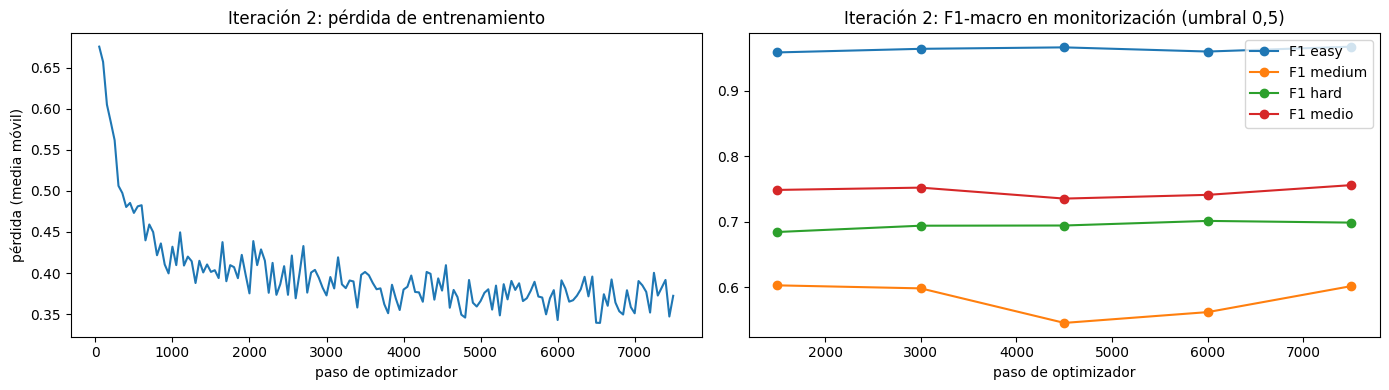

,F1 easy,F1 medium,F1 hard,F1 medio
update,,,,
1500,0.9585,0.6031,0.6845,0.7487
3000,0.9640,0.5985,0.6941,0.7522
4500,0.9662,0.5458,0.6944,0.7355
6000,0.9598,0.5623,0.7015,0.7412
7500,0.9673,0.6020,0.6988,0.7560


In [75]:
# Utilidades de evaluación compartidas por las iteraciones 2 y 3


def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(history["update"], history["loss"])
    axes[0].set_xlabel("paso de optimizador")
    axes[0].set_ylabel("pérdida (media móvil)")
    axes[0].set_title(f"{title}: pérdida de entrenamiento")
    mon = pd.DataFrame(history["monitor"]).set_index("update")[["F1 easy", "F1 medium", "F1 hard", "F1 medio"]]
    mon.plot(marker="o", ax=axes[1])
    axes[1].set_xlabel("paso de optimizador")
    axes[1].set_title(f"{title}: F1-macro en monitorización (umbral 0,5)")
    plt.tight_layout()
    plt.show()
    return mon.round(4)


def tune_thresholds(df, probs):
    thresholds = np.round(np.arange(0.02, 0.99, 0.01), 2)
    sweep = pd.DataFrame([{"umbral": t, **f1_by_difficulty(df, (probs >= t).astype(int))} for t in thresholds])
    best_global = float(sweep.loc[sweep["F1 medio"].idxmax(), "umbral"])
    best_per_diff = {d: float(sweep.loc[sweep[f"F1 {d}"].idxmax(), "umbral"]) for d in DIFFICULTIES}
    print("Umbral global:", best_global, "| por dificultad:", best_per_diff)
    return sweep, best_global, best_per_diff


def evaluate_on_test(label, iteration, probs, best_global, best_per_diff, train_info, conclusions=("", "", "")):
    # conclusions: texto para la tabla resumen de cada variante (umbral 0,5 / global / por dificultad),
    # escrito tras analizar los resultados de esta misma celda
    per_diff = test_df.difficulty.map(best_per_diff).values
    for (name, pred), conclusion in zip([(f"{label} (umbral 0,5)", probs >= 0.5),
                                         (f"{label} (umbral global {best_global})", probs >= best_global),
                                         (f"{label} (umbral por dificultad)", probs >= per_diff)], conclusions):
        record_score(name, f1_by_difficulty(test_df, pred.astype(int)), train_info, conclusion, iteration=iteration)
    pred = (probs >= per_diff).astype(int)
    PREDS[f"It. {iteration}"] = (probs, pred)
    return pred


def report_test(pred, best_per_diff):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, d in zip(axes, DIFFICULTIES):
        m = (test_df.difficulty == d).values
        print(f"===== {d} (umbral {best_per_diff[d]}) =====")
        print(classification_report(test_df.label.values[m], pred[m], target_names=["sin cambio", "cambio"], digits=4))
        ConfusionMatrixDisplay(confusion_matrix(test_df.label.values[m], pred[m], normalize="true"),
                               display_labels=["sin cambio", "cambio"]).plot(ax=ax, colorbar=False, values_format=".2f")
        ax.set_title(d)
    plt.tight_layout()
    plt.show()


plot_history(history_v2, "Iteración 2")

In [76]:
# Iteración 2: umbral en el subconjunto de validación y evaluación en el test COMPLETO
thr_probs_v2, cost = cached_probs("roberta_v2_thr_probs", V2_DIR, thr_enc, fp32_head=True, desc="Validación (umbral)")
test_probs_v2, cost_test = cached_probs("roberta_v2_test_probs", V2_DIR, test_enc, fp32_head=True, desc="Test")
if cost_test:
    record_cost("It. 2 · inferencia test completo", **cost_test)
print("Valores distintos de probabilidad en test:", len(np.unique(test_probs_v2)), "(it. 1:", len(np.unique(test_probs)), ")")

sweep_v2, best_global_v2, best_per_diff_v2 = tune_thresholds(thr_df, thr_probs_v2)
test_pred_v2 = evaluate_on_test("It. 2 RoBERTa-base", "2", test_probs_v2, best_global_v2, best_per_diff_v2,
                                f"{V2_PAIRS_PER_DIFF:,} pares/dif. ({int(100 * V2_POS_FRACTION)} % cambios), "
                                f"{V2_EPOCHS} época, sin pesos, cabeza fp32",
                                conclusions=("Umbral 0,5 empeora medium: el 35 % de cambios en train desplaza el prior y sube los FP",
                                             "Un único umbral mejora easy/medium a costa de hard (igual que en it. 1)",
                                             "Mejora a la it. 1 en las 3 dificultades (+1,6 pt); FN de hard 50 % -> 45 %"))
pd.DataFrame(SCOREBOARD).round(4)

Valores distintos de probabilidad en test: 497841 (it. 1: 5844 )
Umbral global: 0.65 | por dificultad: {'easy': 0.82, 'medium': 0.9, 'hard': 0.26}


,iteración,experimento,entrenamiento,F1 easy,F1 medium,F1 hard,F1 medio,conclusión
0,—,Baseline: siempre «sin cambio»,—,0.4100,0.4889,0.4411,0.4467,Cota inferior trivial
1,—,Baseline: aleatorio estratificado,tasa de cambios de train,0.4984,0.4993,0.5004,0.4994,"Azar informado: F1 ≈ 0,5"
2,1,"RoBERTa-base pares (umbral 0,5)","40,000 pares/dif. (natural), 2 épocas, pesos de clase",0.9553,0.6270,0.7014,0.7612,Easy casi resuelto; en medium y hard se pierde más de la mitad de los cambios (FN)
3,1,RoBERTa-base pares (umbral global 0.68),"40,000 pares/dif. (natural), 2 épocas, pesos de clase",0.9609,0.6384,0.6921,0.7638,Un único umbral no sirve: mejora easy/medium y empeora hard
4,1,RoBERTa-base pares (umbral por dificultad),"40,000 pares/dif. (natural), 2 épocas, pesos de clase",0.9745,0.6454,0.7117,0.7772,Mejor de la it. 1; umbrales muy distintos = modelo no calibrado por dificultad
5,2,"It. 2 RoBERTa-base (umbral 0,5)","80,000 pares/dif. (35 % cambios), 1 época, sin pesos, cabeza fp32",0.9661,0.5998,0.7100,0.7586,"Umbral 0,5 empeora medium: el 35 % de cambios en train desplaza el prior y sube los FP"
6,2,It. 2 RoBERTa-base (umbral global 0.65),"80,000 pares/dif. (35 % cambios), 1 época, sin pesos, cabeza fp32",0.9726,0.6372,0.6959,0.7686,Un único umbral mejora easy/medium a costa de hard (igual que en it. 1)
7,2,It. 2 RoBERTa-base (umbral por dificultad),"80,000 pares/dif. (35 % cambios), 1 época, sin pesos, cabeza fp32",0.9767,0.6736,0.7290,0.7931,"Mejora a la it. 1 en las 3 dificultades (+1,6 pt); FN de hard 50 % -> 45 %"


===== easy (umbral 0.82) =====
              precision    recall  f1-score   support

  sin cambio     0.9842    0.9875    0.9858     81707
      cambio     0.9712    0.9639    0.9675     35862

    accuracy                         0.9803    117569
   macro avg     0.9777    0.9757    0.9767    117569
weighted avg     0.9802    0.9803    0.9802    117569

===== medium (umbral 0.9) =====
              precision    recall  f1-score   support

  sin cambio     0.9718    0.9712    0.9715    266967
      cambio     0.3733    0.3782    0.3757     12093

    accuracy                         0.9455    279060
   macro avg     0.6725    0.6747    0.6736    279060
weighted avg     0.9459    0.9455    0.9457    279060

===== hard (umbral 0.26) =====
              precision    recall  f1-score   support

  sin cambio     0.8824    0.8954    0.8889    100410
      cambio     0.5857    0.5536    0.5692     26827

    accuracy                         0.8233    127237
   macro avg     0.7341    0.7245 

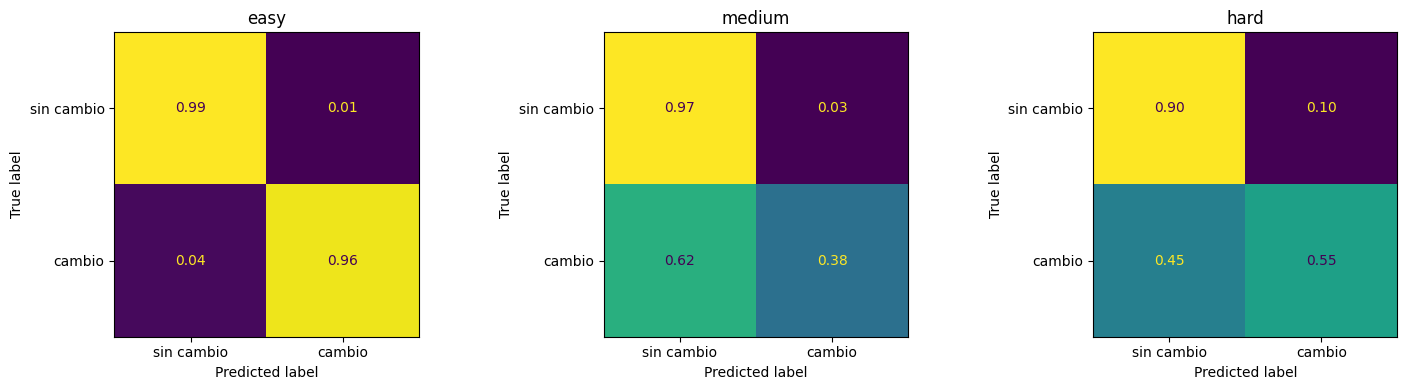

In [77]:
report_test(test_pred_v2, best_per_diff_v2)

### Resultado de la iteración 2

Comparación con la iteración 1 en test, en ambos casos con umbral por dificultad ajustado en validación:

| | It. 1 | It. 2 | Cambio |
|---|---|---|---|
| F1 *easy* | 0,9745 | 0,9767 | +0,2 |
| F1 *medium* | 0,6454 | 0,6736 | **+2,8** |
| F1 *hard* | 0,7117 | 0,7290 | **+1,7** |
| F1 medio | 0,7772 | 0,7931 | +1,6 |
| Cambios perdidos (FN) en *medium* / *hard* | 66,1 % / 50,1 % | 62,2 % / 44,6 % | −3,9 / −5,5 |
| Umbrales óptimos (*easy* / *medium* / *hard*) | 0,94 / 0,85 / 0,32 | 0,82 / 0,90 / 0,26 | Siguen muy separados |
| Valores distintos de probabilidad en test | 5.844 | 497.841 | Cabeza en fp32 |

**Lo que ha funcionado:**
- **Más positivos y más datos distintos.** Mejoran *medium* y *hard*, que eran el objetivo, y bajan los falsos negativos. La única contrapartida es un ligero aumento de falsas alarmas en *hard* (9,7 % → 10,5 %).
- **La cabeza en fp32.** Elimina la cuantización de las probabilidades (de ~6.000 a ~500.000 valores distintos), así que el barrido de umbrales ya es fino.
- **El coste se mantiene.** Ver el doble de pares distintos en una sola época cuesta casi lo mismo que la iteración 1 (37,6 frente a 32,4 min).

**Lo que no ha funcionado o queda pendiente:**
- **Con umbral 0,5, *medium* empeora (0,627 → 0,600).** Es lo esperado: el modelo ha visto un 35 % de cambios en entrenamiento, pero en *medium* real solo hay un 4 %, así que sobreestima la probabilidad de cambio y genera falsos positivos. El submuestreo obliga a recalibrar el umbral, y por eso se ajusta en validación.
- **Los umbrales óptimos siguen muy separados (0,26 en *hard* frente a 0,90 en *medium*).** El modelo sigue sin saber en qué dificultad está, lo que confirma la motivación de la iteración 3.
- **La curva del monitor oscila** (*medium* 0,60 → 0,55 → 0,60) y el mejor checkpoint es el último. Más datos o más pasos podrían seguir ayudando, pero no se ha probado por coste.
- **En *medium* se siguen perdiendo el 62 % de los cambios.** Con solo un 4 % de positivos, el umbral que maximiza el F1-macro (0,90) prima la precisión. Precisión y *recall* de la clase «cambio» quedan ambas en torno a 0,38.

## 9. Iteración 3: condicionar el modelo a la dificultad

**Motivación (punto 3 del diagnóstico).** En la iteración 1 los umbrales óptimos son muy distintos por dificultad (0,94 / 0,85 / 0,32). Con el mismo par de oraciones, un cambio es mucho más probable en *easy* (30 %) que en *medium* (4 %), y el tipo de evidencia también varía: en *easy* el tema delata el cambio y en *hard* solo queda el estilo. El modelo no puede saber nada de esto porque solo ve el par.

**Cambio (único respecto a la iteración 2).** Se antepone la dificultad como texto a la entrada:

`<s> hard </s></s> oración_i </s></s> oración_i+1 </s>`

| Aspecto | Iteración 2 | Iteración 3 | Por qué |
|---|---|---|---|
| Entrada | `<s> oración_i </s></s> oración_i+1 </s>` | **`<s> dificultad </s></s> oración_i </s></s> oración_i+1 </s>`** | Permite al modelo aprender un *prior* y unos rasgos distintos para cada dificultad. |
| Resto | — | Idéntico a la iteración 2: mismos datos, semilla e hiperparámetros | Así la diferencia de resultados se debe solo a este cambio (ablación limpia). |

**¿Es legítimo usar la dificultad?** Sí. En PAN cada dificultad es un conjunto de datos separado y conocido en el momento de la predicción, y el umbral por dificultad de las iteraciones anteriores ya usa esa información. `easy`, `medium` y `hard` son palabras del vocabulario de RoBERTa (un token cada una), así que no se añaden embeddings nuevos. La alternativa, entrenar tres modelos separados, triplicaría el coste y dejaría a cada uno con un tercio de los datos.

Tokenización: 85 s
Ejemplo: <s>easy</s></s>It was a well-acknowledged truth among all the dwarrow-kind that each of Mahal’s children was made unique with their own talents and preferences, but above all they were made with deep-
Modelo ya entrenado en models\roberta-base-pairs-v3-difficulty: se carga de disco (pon RETRAIN=True para reentrenar)
Entrenamiento: 144.8 min | memoria pico 3.18 GB


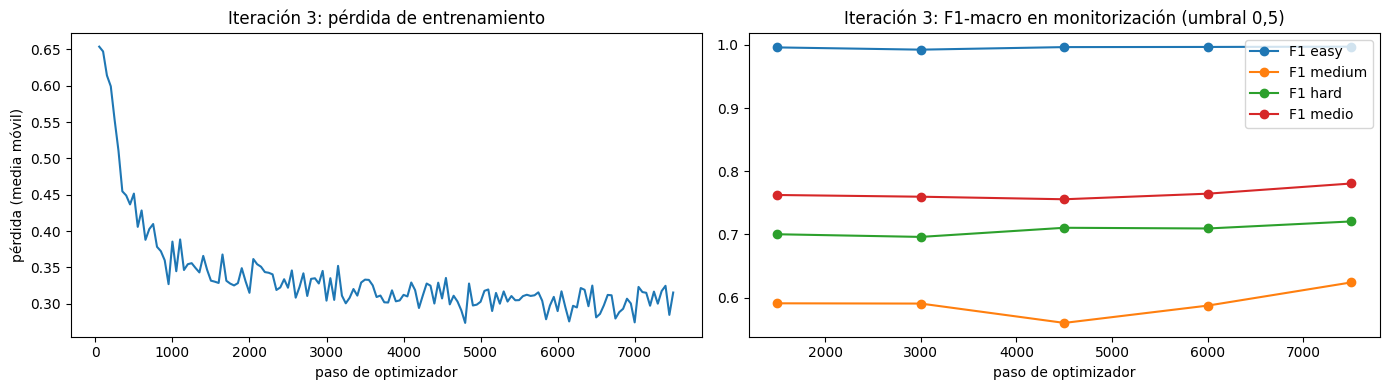

,F1 easy,F1 medium,F1 hard,F1 medio
update,,,,
1500,0.9959,0.5909,0.7002,0.7623
3000,0.9924,0.5905,0.6960,0.7596
4500,0.9964,0.5599,0.7105,0.7556
6000,0.9966,0.5873,0.7093,0.7644
7500,0.9971,0.6240,0.7205,0.7805


In [78]:
V3_DIR = MODEL_DIR.parent / "roberta-base-pairs-v3-difficulty"

# Ya no hacen falta las codificaciones sin prefijo de la iteración 2 (sus probabilidades están guardadas)
release("train_v2_enc", "thr_enc", "test_enc")
with Measure() as m:
    train_v3_enc = encode(train_v2_df, difficulty_prefix=True)
    monitor_v3_enc = encode(monitor_df, difficulty_prefix=True)
    thr_v3_enc = encode(thr_df, difficulty_prefix=True)
    test_v3_enc = encode(test_df, difficulty_prefix=True)
print(f"Tokenización: {m.seconds:.0f} s")
print("Ejemplo:", tokenizer.decode(train_v3_enc["tokens"][train_v3_enc["offsets"][0]:train_v3_enc["offsets"][1]])[:200])

history_v3 = run_training(V3_DIR, train_v3_enc, monitor_df, monitor_v3_enc, epochs=V2_EPOCHS,
                          use_class_weights=False, eval_every=V2_EVAL_EVERY, fp32_head=True)
record_cost("It. 3 · fine-tuning", **{
    "segundos": round(history_v3["train_seconds"]), "memoria pico (GB)": round(history_v3["train_peak_gb"], 2),
    "pares de train": len(train_v2_df), "épocas": V2_EPOCHS, "batch físico": PHYSICAL_BATCH_SIZE,
    "pares/s": round(V2_EPOCHS * len(train_v2_df) / history_v3["train_seconds"], 1)})
plot_history(history_v3, "Iteración 3")

In [79]:
thr_probs_v3, _ = cached_probs("roberta_v3_thr_probs", V3_DIR, thr_v3_enc, fp32_head=True, desc="Validación (umbral)")
test_probs_v3, cost_test = cached_probs("roberta_v3_test_probs", V3_DIR, test_v3_enc, fp32_head=True, desc="Test")
if cost_test:
    record_cost("It. 3 · inferencia test completo", **cost_test)

sweep_v3, best_global_v3, best_per_diff_v3 = tune_thresholds(thr_df, thr_probs_v3)
test_pred_v3 = evaluate_on_test("It. 3 RoBERTa-base + dificultad", "3", test_probs_v3, best_global_v3, best_per_diff_v3,
                                "Ídem it. 2 + dificultad como prefijo",
                                conclusions=("Sin ajustar umbral ya supera a la it. 2 con 0,5 (+2,4 pt): mejor calibrado",
                                             "Un solo umbral iguala al mejor resultado de la it. 2",
                                             "Mejor modelo: easy resuelto; medium/hard apenas mejoran (+0,7/+0,2 pt)"))
pd.DataFrame(SCOREBOARD).round(4)

Umbral global: 0.72 | por dificultad: {'easy': 0.98, 'medium': 0.82, 'hard': 0.54}


,iteración,experimento,entrenamiento,F1 easy,F1 medium,F1 hard,F1 medio,conclusión
0,—,Baseline: siempre «sin cambio»,—,0.4100,0.4889,0.4411,0.4467,Cota inferior trivial
1,—,Baseline: aleatorio estratificado,tasa de cambios de train,0.4984,0.4993,0.5004,0.4994,"Azar informado: F1 ≈ 0,5"
2,1,"RoBERTa-base pares (umbral 0,5)","40,000 pares/dif. (natural), 2 épocas, pesos de clase",0.9553,0.6270,0.7014,0.7612,Easy casi resuelto; en medium y hard se pierde más de la mitad de los cambios (FN)
3,1,RoBERTa-base pares (umbral global 0.68),"40,000 pares/dif. (natural), 2 épocas, pesos de clase",0.9609,0.6384,0.6921,0.7638,Un único umbral no sirve: mejora easy/medium y empeora hard
4,1,RoBERTa-base pares (umbral por dificultad),"40,000 pares/dif. (natural), 2 épocas, pesos de clase",0.9745,0.6454,0.7117,0.7772,Mejor de la it. 1; umbrales muy distintos = modelo no calibrado por dificultad
5,2,"It. 2 RoBERTa-base (umbral 0,5)","80,000 pares/dif. (35 % cambios), 1 época, sin pesos, cabeza fp32",0.9661,0.5998,0.7100,0.7586,"Umbral 0,5 empeora medium: el 35 % de cambios en train desplaza el prior y sube los FP"
6,2,It. 2 RoBERTa-base (umbral global 0.65),"80,000 pares/dif. (35 % cambios), 1 época, sin pesos, cabeza fp32",0.9726,0.6372,0.6959,0.7686,Un único umbral mejora easy/medium a costa de hard (igual que en it. 1)
7,2,It. 2 RoBERTa-base (umbral por dificultad),"80,000 pares/dif. (35 % cambios), 1 época, sin pesos, cabeza fp32",0.9767,0.6736,0.7290,0.7931,"Mejora a la it. 1 en las 3 dificultades (+1,6 pt); FN de hard 50 % -> 45 %"
8,3,"It. 3 RoBERTa-base + dificultad (umbral 0,5)",Ídem it. 2 + dificultad como prefijo,0.9970,0.6208,0.7299,0.7825,"Sin ajustar umbral ya supera a la it. 2 con 0,5 (+2,4 pt): mejor calibrado"
9,3,It. 3 RoBERTa-base + dificultad (umbral global 0.72),Ídem it. 2 + dificultad como prefijo,0.9970,0.6754,0.7142,0.7956,Un solo umbral iguala al mejor resultado de la it. 2


===== easy (umbral 0.98) =====
              precision    recall  f1-score   support

  sin cambio     0.9987    0.9982    0.9984     81707
      cambio     0.9959    0.9970    0.9964     35862

    accuracy                         0.9978    117569
   macro avg     0.9973    0.9976    0.9974    117569
weighted avg     0.9978    0.9978    0.9978    117569

===== medium (umbral 0.82) =====
              precision    recall  f1-score   support

  sin cambio     0.9719    0.9738    0.9729    266967
      cambio     0.3963    0.3793    0.3876     12093

    accuracy                         0.9481    279060
   macro avg     0.6841    0.6766    0.6802    279060
weighted avg     0.9470    0.9481    0.9475    279060

===== hard (umbral 0.54) =====
              precision    recall  f1-score   support

  sin cambio     0.8799    0.9065    0.8930    100410
      cambio     0.6054    0.5370    0.5691     26827

    accuracy                         0.8286    127237
   macro avg     0.7426    0.7217

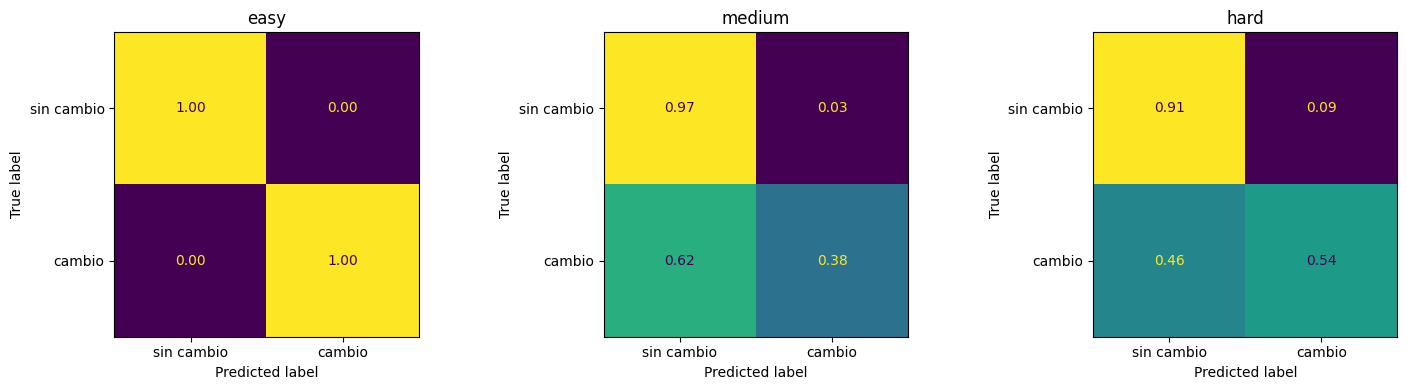

In [80]:
report_test(test_pred_v3, best_per_diff_v3)

### Resultado de la iteración 3

Esta iteración es una ablación: el único cambio respecto a la iteración 2 es el prefijo con la dificultad.

| | It. 2 | It. 3 | Cambio |
|---|---|---|---|
| F1 medio con umbral 0,5 | 0,7586 | 0,7825 | **+2,4** |
| F1 medio con umbral global | 0,7686 (0,65) | 0,7956 (0,72) | **+2,7** |
| F1 *easy* (umbral por dificultad) | 0,9767 | **0,9974** | +2,1 |
| F1 *medium* (umbral por dificultad) | 0,6736 | 0,6802 | +0,7 |
| F1 *hard* (umbral por dificultad) | 0,7290 | 0,7311 | +0,2 |
| F1 medio (umbral por dificultad) | 0,7931 | **0,8029** | +1,0 |
| Umbrales óptimos (*easy* / *medium* / *hard*) | 0,82 / 0,90 / 0,26 | 0,98 / 0,82 / 0,54 | *Hard* pasa a ~0,5 |
| Errores en *easy* (FN / FP) | 3,6 % / 1,3 % | 0,3 % / 0,2 % | Unas 10 veces menos |

**Respuesta a las preguntas planteadas:**
- **¿Mejora la calibración?** Sí, en parte.
  - Con el umbral por defecto (0,5) el modelo gana 2,4 puntos sin ajustar nada.
  - Un único umbral global ya iguala lo que en la iteración 2 requería tres umbrales.
  - El umbral de *hard* pasa de 0,26 a 0,54 y el de *medium* de 0,90 a 0,82, más cerca de 0,5.
  - *Easy* se va a 0,98, pero su curva de F1 es casi plana en la zona alta, así que el umbral exacto apenas importa.
- **¿Dónde está la mejora?** Sobre todo en ***easy***, que pasa a estar prácticamente resuelto. Al saber que el documento es *easy*, el modelo puede apoyarse sin miedo en el cambio de tema, que en *hard* sería engañoso. En *medium* y *hard* la ganancia es marginal (+0,7 y +0,2 puntos) y queda dentro de lo que podría explicar la variabilidad entre semillas, que no se ha medido.
- **Conclusión.** La dificultad como prefijo es útil y barata (+1 punto de F1 medio, un token más por par), pero **no ataca el cuello de botella real**. En *medium* y *hard* el par de oraciones aislado no contiene suficiente señal de estilo.

**Coste.** El entrenamiento tardó 144,8 min, frente a 37,6 en la iteración 2, con la misma memoria pico. No se debe al prefijo:
- El prefijo solo añade unos 3–4 tokens por par (≈ +10 %).
- La inferencia del subconjunto de umbral, en la misma sesión, fue igual de rápida que en la iteración 2 (≈ 330 pares/s).

Al principio se atribuyó a la máquina (*throttling* del portátil). El intento de la iteración 4 con entradas más largas reveló la causa real: la memoria de la GPU se **desbordaba a memoria compartida** (RAM del sistema) tras las evaluaciones intermedias (ver sección 10). Esto solo afecta al tiempo, no a los resultados.

## 10. Diagnóstico de la iteración 3

Antes de decidir el siguiente cambio se analizan los errores del mejor modelo (iteración 3) **en validación**: el subconjunto de 120.000 pares que se usó para ajustar el umbral. No se usa el test, para no adaptar las decisiones a él.

> **Intento descartado.** La primera idea para la iteración 4 era dar al modelo una oración de contexto a cada lado del punto de corte (entradas de hasta 231 tokens). Se interrumpió a mitad del entrenamiento por un problema de memoria:
> - Con secuencias tan largas, la memoria extra que reserva cada evaluación intermedia se sumaba a la del entrenamiento.
> - Windows desbordaba el exceso a **memoria compartida** (RAM del sistema): el proceso usaba 3,65 GB de la GPU más 2,5 GB de RAM.
> - Cada paso tardaba 3–4 veces más. Esto explica también los 145 min de la iteración 3, que se atribuyeron inicialmente al portátil.
>
> Se corrigió en `train_model`, que ahora usa un batch de evaluación menor y libera la caché de memoria tras cada evaluación.
>
> En lugar de relanzar esa idea, primero se hizo este diagnóstico, que **desaconseja** el contexto de una sola oración en *hard* (punto 3).

In [81]:
# Errores de la iteración 3 en el subconjunto de validación del umbral, con su umbral por dificultad
diag3 = thr_df.assign(p=thr_probs_v3)
diag3["pred"] = (diag3.p >= diag3.difficulty.map(best_per_diff_v3)).astype(int)

# Longitud de los segmentos de autor alrededor de cada frontera (a partir de las etiquetas de validación completa)
seg_parts = []
for (d, pid), g in val_df.sort_values(key_cols).groupby(["difficulty", "problem_id"], sort=False):
    lab = g.label.values
    seg_id = np.r_[0, np.cumsum(lab)]                 # segmento de cada oración
    seg_len = np.bincount(seg_id)
    seg_parts.append(pd.DataFrame({"difficulty": d, "problem_id": pid, "idx": g.idx.values,
                                   "seg_antes": seg_len[seg_id[:-1]], "seg_despues": seg_len[seg_id[1:]]}))
diag3 = diag3.merge(pd.concat(seg_parts), on=key_cols, how="left", validate="one_to_one")


def jaccard(a, b):
    A, B = set(re.findall(r"\w+", a.lower())), set(re.findall(r"\w+", b.lower()))
    return len(A & B) / len(A | B) if A | B else 0.0


diag3["solapamiento"] = [jaccard(a, b) for a, b in zip(diag3.sent_a, diag3.sent_b)]
diag3["palabras_min"] = np.minimum(diag3.sent_a.str.count(r"\S+"), diag3.sent_b.str.count(r"\S+"))
cambios3 = diag3[diag3.label == 1].assign(FN=lambda x: (x.pred == 0).astype(int))


def pct_fn(col, bins):
    out = {}
    for d in ["medium", "hard"]:
        g = cambios3[cambios3.difficulty == d]
        out[d] = g.groupby(pd.cut(g[col], bins, include_lowest=True), observed=True).FN.agg(
            **{"% FN": lambda s: round(100 * s.mean(), 1), "cambios": "size"})
    return pd.concat(out, axis=1)


print("1) ¿Fallos seguros o dudosos? (probabilidad asignada a los cambios perdidos)")
for d in ["medium", "hard"]:
    p = cambios3[(cambios3.difficulty == d) & (cambios3.FN == 1)].p
    print(f"   {d}: mediana p = {p.median():.2f} | p < 0,1: {(p < 0.1).mean():.0%} | "
          f"a menos de 0,15 del umbral ({best_per_diff_v3[d]}): {(p > best_per_diff_v3[d] - 0.15).mean():.0%}")
print("\n2) % de cambios perdidos según el solapamiento léxico (Jaccard) entre las dos oraciones")
display(pct_fn("solapamiento", [0, 0.05, 0.1, 0.2, 0.3, 1]))
print("3) % de cambios perdidos según la longitud (oraciones) del segmento de autor ANTERIOR al cambio")
display(pct_fn("seg_antes", [0, 1, 2, 3, 5, 10, 1000]))
print("4) % de cambios perdidos según la longitud (palabras) de la oración más corta del par")
display(pct_fn("palabras_min", [0, 15, 20, 30, 300]))

1) ¿Fallos seguros o dudosos? (probabilidad asignada a los cambios perdidos)
   medium: mediana p = 0.49 | p < 0,1: 8% | a menos de 0,15 del umbral (0.82): 17%
   hard: mediana p = 0.36 | p < 0,1: 7% | a menos de 0,15 del umbral (0.54): 44%

2) % de cambios perdidos según el solapamiento léxico (Jaccard) entre las dos oraciones


medium          hard        
                 % FN cambios  % FN cambios
solapamiento                               
(-0.001, 0.05]   57.4   451.0  38.3     358
(0.05, 0.1]      61.2   898.0  42.3    2474
(0.1, 0.2]       67.8   425.0  49.3    5260
(0.2, 0.3]       60.0     5.0  54.8     438
(0.3, 1.0]        NaN     NaN  78.6      14

3) % de cambios perdidos según la longitud (oraciones) del segmento de autor ANTERIOR al cambio


medium          hard        
                 % FN cambios  % FN cambios
seg_antes                                  
(-0.001, 1.0]    62.6     725  49.3    3698
(1.0, 2.0]       67.3     162  48.0    1590
(2.0, 3.0]       62.5      88  45.2     803
(3.0, 5.0]       51.4     111  46.2     893
(5.0, 10.0]      62.5     152  43.6     906
(10.0, 1000.0]   61.0     541  41.3     654

4) % de cambios perdidos según la longitud (palabras) de la oración más corta del par


medium          hard        
                 % FN cambios  % FN cambios
palabras_min                               
(-0.001, 15.0]   78.9      19  50.0      70
(15.0, 20.0]     64.9     713  46.8    3273
(20.0, 30.0]     60.7     911  47.0    4366
(30.0, 300.0]    50.7     136  48.7     835

In [82]:
# Ejemplos: cambios de 'hard' que el modelo pierde con más seguridad (probabilidad más baja)
for r in cambios3[(cambios3.difficulty == "hard") & (cambios3.FN == 1)].nsmallest(4, "p").itertuples():
    print(f"p = {r.p:.4f} | segmento antes/después del cambio: {r.seg_antes}/{r.seg_despues} oraciones")
    print("   [i]  ", r.sent_a[:170])
    print("   ---- cambio de autor ----")
    print("   [i+1]", r.sent_b[:170], "\n")

p = 0.0025 | segmento antes/después del cambio: 1/26 oraciones
   [i]   Toph followed him outside, “Aren't you going to finish your Tea, it’s going cold” “It’s ok Toph, you can finish it, but..”, Aang wanted to be away from Katara and Zuko fo
   ---- cambio de autor ----
   [i+1] Before Aang could respond Zuko butted in, “Not to break up this epiphany, but I just wanted to take your order, what do you want?” “I’ll have a pot of Iroh’s famous jasmi 

p = 0.0036 | segmento antes/después del cambio: 1/7 oraciones
   [i]   “You’ve no idea,” Isabela says, stroking a hand over the high collar covering Hawke’s throat down to her fabric-covered breasts, “how long I’ve been waiting to get you ou
   ---- cambio de autor ----
   [i+1] “I’ve been waiting so long,” Isabela tells her, lips on her neck and fingers slipping back below the waist of her jeans, “waiting to be sure that you wanted me like I wan 

p = 0.0038 | segmento antes/después del cambio: 2/7 oraciones
   [i]   "None of them spared m

### Conclusiones del diagnóstico de la iteración 3

1. **El modelo duda más que equivocarse con seguridad.**
   - En *hard*, la mitad de los cambios perdidos tienen p ≥ 0,36 y el 44 % están a menos de 0,15 del umbral. Solo un 7 % tienen p < 0,1.
   - En *medium*, la mediana de los perdidos es 0,49 con un umbral de 0,82. El umbral es tan alto porque, con un 4 % de cambios, bajarlo dispara los falsos positivos.
   - Le falta **evidencia adicional** para inclinar la decisión, no está «ciego».
2. **Se fía del contenido, no del estilo.** En *hard*, el porcentaje de cambios perdidos sube con el solapamiento léxico: 38 % con menos de 0,05 de Jaccard, 49 % con 0,1–0,2 y 79 % por encima de 0,3.
   - En los ejemplos, el nuevo autor sigue con los mismos personajes y la misma escena, y el modelo concluye «mismo autor».
   - Es el atajo «mismo tema = mismo autor», útil en *easy* y engañoso en *hard*.
3. **En *hard* los autores se alternan muy rápido.** El 43 % de los cambios llegan tras un segmento de **una sola oración**, así que la oración anterior suele ser de otro autor. Por eso añadir una oración de contexto a la entrada (el intento descartado) mezclaría autores en *hard*.
4. **La longitud de las oraciones no explica los errores.** Todas tienen al menos 10 palabras, y la posición en el documento tampoco influye.

**Consecuencia para la iteración 4.** Hacen falta señales que RoBERTa no está usando, y que se puedan combinar con su probabilidad sin reentrenarlo:
- **Lo que pasa en las fronteras vecinas** (punto 1).
- **Rasgos de estilo explícitos y no temáticos:** puntuación, comillas tipográficas o rectas, guiones, palabras funcionales… (punto 2).
- **El propio solapamiento léxico**, para que el modelo aprenda a desconfiar de RoBERTa cuando el tema es el mismo (punto 2).
- **Ventanas de varias oraciones** comparadas por rasgos agregados, en lugar de texto concatenado (punto 3).

## 11. Iteración 4: modelo de segundo nivel (RoBERTa + estilo explícito + contexto del documento)

**Idea.** El *cross-encoder* de la iteración 3 se mantiene tal cual y su probabilidad pasa a ser **una señal más** de un clasificador de segundo nivel (*gradient boosting*, uno por dificultad). Ese clasificador ve, para cada frontera:

| Grupo de rasgos | Qué contiene | Problema del diagnóstico que ataca |
|---|---|---|
| Probabilidad de RoBERTa | *p* y logit en la frontera, *p* en las 3 fronteras anteriores y las 3 posteriores, «pico» respecto a las vecinas, media, máximo y rango de *p* en el documento | (1) Decisiones dudosas: el patrón del documento puede inclinar la balanza. |
| Estilo de cada oración | Comillas curvas o rectas, apóstrofos, puntos suspensivos («…» o «...»), guiones (—, –, --), punto y coma, exclamaciones, paréntesis, mayúsculas, «i» minúscula, contracciones, palabras funcionales, longitud de palabra… (33 rasgos) | (2) Señales de autor que no dependen del tema. |
| Diferencias de estilo | \|rasgo(*i*) − rasgo(*i+1*)\| y diferencia entre la media de las 3 oraciones anteriores y las 3 posteriores | (2) y (3): comparación de estilos sobre más texto sin mezclar autores en la entrada. |
| Tema | Jaccard entre las dos oraciones y nº de nombres propios compartidos | (2) Permite aprender a desconfiar del atajo temático. |

**Cómo se entrena sin contaminar el test.**
- El segundo nivel se entrena con la **validación completa**: los ~524.000 pares que RoBERTa no vio al entrenar.
- Se usa **validación cruzada de 5 particiones agrupadas por documento**, de modo que ningún documento está a la vez en entrenamiento y evaluación de un *fold*.
- Las predicciones fuera de *fold* (OOF) sirven para medir la mejora y elegir el umbral.
- El modelo final se entrena con toda la validación y se aplica **una sola vez** al test.
- Ningún rasgo usa etiquetas: solo texto y predicciones de RoBERTa, disponibles en test porque PAN entrega el documento completo.

**Ablación.** Con validación cruzada también se mide el segundo nivel **solo con los rasgos de probabilidad**, sin estilo ni tema. Así se sabe cuánto aporta el contexto del documento y cuánto el estilo explícito.

**Coste.** Una inferencia de RoBERTa sobre la validación completa (~30 min de GPU, se guarda en caché). El resto es CPU: unos minutos de rasgos y del orden de 10–20 min de *gradient boosting*.

In [83]:
# 11.1 Probabilidades de la iteración 3 en la validación COMPLETA (necesarias para entrenar el 2º nivel)
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold

release("train_v3_enc", "monitor_v3_enc", "thr_v3_enc", "test_v3_enc")
val_v3_enc = encode(val_df, difficulty_prefix=True)
val_probs_v3, cost_val = cached_probs("roberta_v3_val_probs", V3_DIR, val_v3_enc, fp32_head=True, desc="Validación completa")
release("val_v3_enc")
if cost_val:
    record_cost("It. 4 · inferencia RoBERTa it. 3 en validación completa", **cost_val)
print("F1 de RoBERTa it. 3 en la validación completa (umbral 0,5):", f1_by_difficulty(val_df, (val_probs_v3 >= 0.5).astype(int)))

F1 de RoBERTa it. 3 en la validación completa (umbral 0,5): {'F1 easy': 0.9969092998293366, 'F1 medium': 0.6233469106286867, 'F1 hard': 0.7264589555169394, 'F1 medio': 0.782238388658321}


In [84]:
# 11.2 Rasgos del segundo nivel
FUNCTION_WORDS = ("the a an and but or of to in on at for with by from as that this it is was be "
                  "he she they i you we his her their my your our not so then just very").split()
STYLE_PATTERNS = {
    "q_curly_d": r"[“”]", "q_straight_d": r'"', "q_curly_s": r"[‘’]", "q_straight_s": r"'",
    "ellipsis_char": r"…", "three_dots": r"\.\.\.", "em_dash": r"—", "en_dash": r"–", "dbl_hyphen": r"--",
    "spaced_hyphen": r" - ", "semicolon": r";", "colon": r":", "excl": r"!", "quest": r"\?", "comma": r",",
    "paren": r"\(", "digit": r"\d", "upper": r"[A-Z]", "asterisk": r"\*", "tilde": r"~", "dbl_space": r"  ",
    "lower_i": r"(?:^|\s)i(?:\s|')", "contraction": r"n[’']t\b", "allcaps_word": r"\b[A-Z]{2,}\b",
    "space_before_punct": r" [,.!?;:]", "nonascii": r"[^\x00-\x7f]",
}
FW_RE = r"\b(?:" + "|".join(FUNCTION_WORDS) + r")\b"


def sentence_style(text):
    # Rasgos de estilo de cada oración, normalizados por nº de palabras (vectorizado con pandas.str)
    s = text.fillna("")
    n_word = s.str.count(r"\S+").clip(lower=1)
    f = {"n_char": s.str.len(), "n_word": n_word, "avg_word_len": s.str.count(r"\w") / n_word,
         "fw_ratio": s.str.lower().str.count(FW_RE) / n_word,
         "starts_lower": s.str.match(r"^[a-z]").astype(float),
         "starts_quote": s.str.match(r"^[\"“‘']").astype(float),
         "ends_no_punct": (~s.str.contains(r"[.!?…\"”’')]\s*$")).astype(float)}
    for name, pat in STYLE_PATTERNS.items():
        f[name] = s.str.count(pat) / n_word
    return pd.DataFrame(f).astype(np.float32)


def stacking_features(df, p):
    # df: TODOS los pares de un split (todas las fronteras de cada documento); p: probabilidad de la it. 3
    df = df.assign(p=p).sort_values(key_cols).reset_index()      # 'index' = posición original
    doc = (df.difficulty + "/" + df.problem_id.astype(str)).values
    doc_id = np.cumsum(np.r_[True, doc[1:] != doc[:-1]]) - 1
    n = len(df)
    # Tabla de oraciones: la j-ésima es sent_a del par j; la última de cada documento, sent_b de su último par
    last = np.r_[doc_id[1:] != doc_id[:-1], True]
    sent_doc = np.r_[doc_id, doc_id[last]]
    sent_pos = np.r_[df.idx.values, df.idx.values[last] + 1]
    order = np.lexsort((sent_pos, sent_doc))
    sent_text = pd.concat([df.sent_a, df.sent_b[last]]).iloc[order].reset_index(drop=True)
    sent_doc = sent_doc[order]
    S_df = sentence_style(sent_text)
    names, S = list(S_df.columns), S_df.values
    first_sent = np.flatnonzero(np.r_[True, sent_doc[1:] != sent_doc[:-1]])
    end_sent = np.r_[first_sent[1:], len(sent_doc)]
    a_idx = first_sent[doc_id] + df.idx.values
    b_idx = a_idx + 1
    lo, hi = first_sent[doc_id], end_sent[doc_id]

    out = {}
    for j, nm in enumerate(names):
        out[f"a_{nm}"], out[f"b_{nm}"] = S[a_idx, j], S[b_idx, j]
        out[f"d_{nm}"] = np.abs(S[a_idx, j] - S[b_idx, j])
    # Ventanas: media de las 3 oraciones anteriores (i-2..i) frente a las 3 posteriores (i+1..i+3), sin salir del documento
    C = np.vstack([np.zeros((1, S.shape[1])), np.cumsum(S, axis=0)])
    win = lambda l, h: (C[h] - C[l]) / np.maximum(h - l, 1)[:, None]
    wdiff = np.abs(win(np.maximum(a_idx - 2, lo), a_idx + 1) - win(b_idx, np.minimum(b_idx + 3, hi)))
    for j, nm in enumerate(names):
        out[f"wd_{nm}"] = wdiff[:, j]
    # Probabilidad de RoBERTa en la frontera, en las vecinas y en el documento
    pv = df.p.values.astype(np.float32)
    out["p"] = pv
    out["logit"] = np.log(np.clip(pv, 1e-6, 1 - 1e-6) / np.clip(1 - pv, 1e-6, 1))
    for k in (-3, -2, -1, 1, 2, 3):
        src = np.clip(np.arange(n) + k, 0, n - 1)
        ok = (np.arange(n) + k >= 0) & (np.arange(n) + k < n) & (doc_id[src] == doc_id)
        out[f"p_{k:+d}"] = np.where(ok, pv[src], np.nan)
    out["p_peak"] = pv - np.fmax(np.nan_to_num(out["p_-1"]), np.nan_to_num(out["p_+1"]))
    g = pd.Series(pv).groupby(doc_id)
    out["doc_mean_p"], out["doc_max_p"] = g.transform("mean").values, g.transform("max").values
    out["doc_n_pairs"] = g.transform("size").values.astype(np.float32)
    out["doc_n_hi"] = pd.Series(pv > 0.5).groupby(doc_id).transform("sum").values.astype(np.float32)
    out["doc_rank"] = g.rank(pct=True).values
    out["rel_pos"] = df.idx.values / out["doc_n_pairs"]
    # Tema: solapamiento léxico y nombres propios compartidos
    wa, wb = df.sent_a.str.lower().str.findall(r"\w+").map(set), df.sent_b.str.lower().str.findall(r"\w+").map(set)
    out["jaccard"] = np.array([len(x & y) / max(len(x | y), 1) for x, y in zip(wa, wb)], dtype=np.float32)
    na, nb = df.sent_a.str.findall(r"\b[A-Z][a-z]+\b").map(set), df.sent_b.str.findall(r"\b[A-Z][a-z]+\b").map(set)
    out["shared_names"] = np.array([len(x & y) for x, y in zip(na, nb)], dtype=np.float32)

    feats = pd.DataFrame(out)
    feats.index = df["index"].values
    feats = feats.sort_index()
    assert np.allclose(feats.p.values, p), "rasgos desalineados con los pares"
    return feats


PROB_FEATURES = ["p", "logit", "p_-3", "p_-2", "p_-1", "p_+1", "p_+2", "p_+3", "p_peak",
                 "doc_mean_p", "doc_max_p", "doc_n_pairs", "doc_n_hi", "doc_rank", "rel_pos"]
with Measure() as m:
    F_val = stacking_features(val_df, val_probs_v3)
    F_test = stacking_features(test_df, test_probs_v3)
print(f"Rasgos: {F_val.shape[1]} por frontera | validación {F_val.shape[0]:,} | test {F_test.shape[0]:,} | {m.seconds:.0f} s")

Rasgos: 149 por frontera | validación 523,803 | test 523,866 | 178 s


In [85]:
# 11.3 Validación cruzada agrupada por documento (solo validación): ¿cuánto mejora el 2º nivel y qué aporta cada grupo?
def make_stacker():
    return HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05, max_leaf_nodes=63, min_samples_leaf=100,
                                          l2_regularization=1.0, early_stopping=False, random_state=SEED)


def oof_probs(columns, n_splits=5):
    oof = np.zeros(len(val_df))
    for d in DIFFICULTIES:
        m = np.flatnonzero((val_df.difficulty == d).values)
        X, y, groups = F_val.iloc[m][columns], val_df.label.values[m], val_df.problem_id.values[m]
        for tr, te in GroupKFold(n_splits=n_splits).split(X, y, groups):
            oof[m[te]] = make_stacker().fit(X.iloc[tr], y[tr]).predict_proba(X.iloc[te])[:, 1]
    return oof


with Measure() as m:
    oof_all = oof_probs(list(F_val.columns))
    oof_prob_only = oof_probs(PROB_FEATURES)
print(f"Validación cruzada: {m.seconds / 60:.1f} min")


def best_per_difficulty(probs):
    _, _, per_diff = tune_thresholds(val_df, probs)
    pred = (probs >= val_df.difficulty.map(per_diff).values).astype(int)
    return f1_by_difficulty(val_df, pred), per_diff


rows = {}
for name, probs in [("RoBERTa it. 3 (umbral ajustado en la propia validación)", val_probs_v3),
                    ("2º nivel solo probabilidades (OOF)", oof_prob_only),
                    ("2º nivel completo (OOF)", oof_all)]:
    rows[name], _ = best_per_difficulty(probs)
pd.DataFrame(rows).T.round(4)

Validación cruzada: 8.8 min
Umbral global: 0.72 | por dificultad: {'easy': 0.98, 'medium': 0.84, 'hard': 0.53}
Umbral global: 0.29 | por dificultad: {'easy': 0.66, 'medium': 0.22, 'hard': 0.36}
Umbral global: 0.3 | por dificultad: {'easy': 0.53, 'medium': 0.24, 'hard': 0.35}


,F1 easy,F1 medium,F1 hard,F1 medio
RoBERTa it. 3 (umbral ajustado en la propia validación),0.9975,0.6849,0.7289,0.8038
2º nivel solo probabilidades (OOF),0.9987,0.6978,0.7284,0.8083
2º nivel completo (OOF),0.9994,0.7064,0.7370,0.8142


In [86]:
# 11.4 Modelo final: se entrena con TODA la validación y se aplica una sola vez al test
_, best_global_v4, best_per_diff_v4 = tune_thresholds(val_df, oof_all)   # umbrales elegidos con las predicciones OOF
test_probs_v4 = np.zeros(len(test_df))
with Measure() as m:
    for d in DIFFICULTIES:
        mv, mt = (val_df.difficulty == d).values, (test_df.difficulty == d).values
        stacker = make_stacker().fit(F_val[mv], val_df.label.values[mv])
        test_probs_v4[mt] = stacker.predict_proba(F_test[mt])[:, 1]
record_cost("It. 4 · 2º nivel (rasgos + entrenamiento + test)", **{"segundos": round(m.seconds)})

test_pred_v4 = evaluate_on_test("It. 4 2º nivel (RoBERTa it. 3 + estilo + documento)", "4", test_probs_v4,
                                best_global_v4, best_per_diff_v4,
                                "Gradient boosting sobre p(it. 3) + 149 rasgos; entrenado en validación",
                                conclusions=("Umbral 0,5 inadecuado: el 2º nivel aprende la tasa real de cambios",
                                             "Un único umbral ya supera a la it. 3 con tres (+1,0 pt)",
                                             "Mejor hasta aquí sin reentrenar RoBERTa: medium +2,2 y hard +1,1 pt"))
pd.DataFrame(SCOREBOARD).round(4)

Umbral global: 0.3 | por dificultad: {'easy': 0.53, 'medium': 0.24, 'hard': 0.35}


,iteración,experimento,entrenamiento,F1 easy,F1 medium,F1 hard,F1 medio,conclusión
0,—,Baseline: siempre «sin cambio»,—,0.4100,0.4889,0.4411,0.4467,Cota inferior trivial
1,—,Baseline: aleatorio estratificado,tasa de cambios de train,0.4984,0.4993,0.5004,0.4994,"Azar informado: F1 ≈ 0,5"
2,1,"RoBERTa-base pares (umbral 0,5)","40,000 pares/dif. (natural), 2 épocas, pesos de clase",0.9553,0.6270,0.7014,0.7612,Easy casi resuelto; en medium y hard se pierde más de la mitad de los cambios (FN)
3,1,RoBERTa-base pares (umbral global 0.68),"40,000 pares/dif. (natural), 2 épocas, pesos de clase",0.9609,0.6384,0.6921,0.7638,Un único umbral no sirve: mejora easy/medium y empeora hard
4,1,RoBERTa-base pares (umbral por dificultad),"40,000 pares/dif. (natural), 2 épocas, pesos de clase",0.9745,0.6454,0.7117,0.7772,Mejor de la it. 1; umbrales muy distintos = modelo no calibrado por dificultad
5,2,"It. 2 RoBERTa-base (umbral 0,5)","80,000 pares/dif. (35 % cambios), 1 época, sin pesos, cabeza fp32",0.9661,0.5998,0.7100,0.7586,"Umbral 0,5 empeora medium: el 35 % de cambios en train desplaza el prior y sube los FP"
6,2,It. 2 RoBERTa-base (umbral global 0.65),"80,000 pares/dif. (35 % cambios), 1 época, sin pesos, cabeza fp32",0.9726,0.6372,0.6959,0.7686,Un único umbral mejora easy/medium a costa de hard (igual que en it. 1)
7,2,It. 2 RoBERTa-base (umbral por dificultad),"80,000 pares/dif. (35 % cambios), 1 época, sin pesos, cabeza fp32",0.9767,0.6736,0.7290,0.7931,"Mejora a la it. 1 en las 3 dificultades (+1,6 pt); FN de hard 50 % -> 45 %"
8,3,"It. 3 RoBERTa-base + dificultad (umbral 0,5)",Ídem it. 2 + dificultad como prefijo,0.9970,0.6208,0.7299,0.7825,"Sin ajustar umbral ya supera a la it. 2 con 0,5 (+2,4 pt): mejor calibrado"
9,3,It. 3 RoBERTa-base + dificultad (umbral global 0.72),Ídem it. 2 + dificultad como prefijo,0.9970,0.6754,0.7142,0.7956,Un solo umbral iguala al mejor resultado de la it. 2


===== easy (umbral 0.53) =====
              precision    recall  f1-score   support

  sin cambio     0.9995    0.9996    0.9996     81707
      cambio     0.9991    0.9989    0.9990     35862

    accuracy                         0.9994    117569
   macro avg     0.9993    0.9992    0.9993    117569
weighted avg     0.9994    0.9994    0.9994    117569

===== medium (umbral 0.24) =====
              precision    recall  f1-score   support

  sin cambio     0.9737    0.9762    0.9749    266967
      cambio     0.4429    0.4169    0.4295     12093

    accuracy                         0.9520    279060
   macro avg     0.7083    0.6966    0.7022    279060
weighted avg     0.9507    0.9520    0.9513    279060

===== hard (umbral 0.35) =====
              precision    recall  f1-score   support

  sin cambio     0.8865    0.9039    0.8951    100410
      cambio     0.6119    0.5667    0.5884     26827

    accuracy                         0.8328    127237
   macro avg     0.7492    0.7353

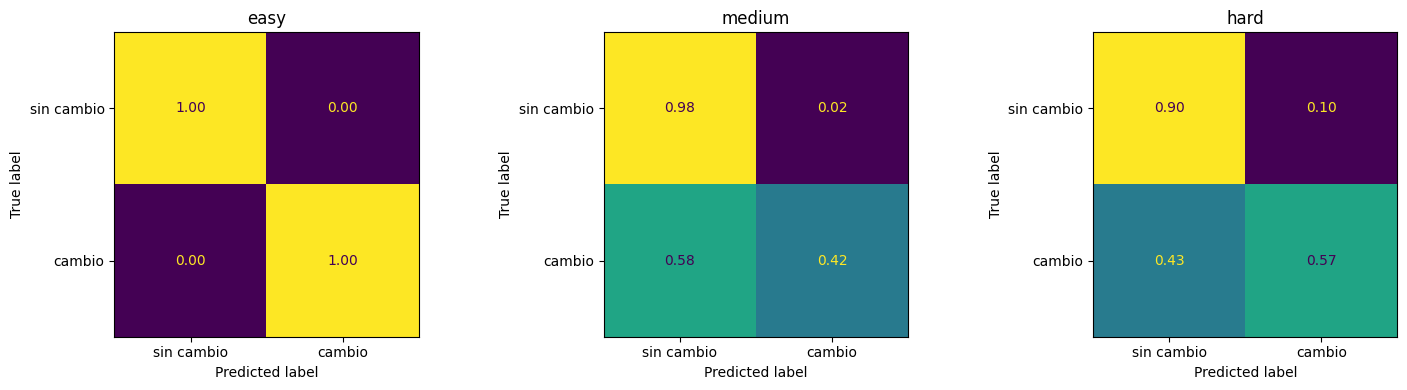

In [87]:
report_test(test_pred_v4, best_per_diff_v4)

### Resultado de la iteración 4

**Ablación en validación** (predicciones fuera de *fold*, umbral por dificultad):

| | *Easy* | *Medium* | *Hard* | Media |
|---|---|---|---|---|
| RoBERTa it. 3 sola | 0,9975 | 0,6849 | 0,7289 | 0,8038 |
| 2º nivel solo con probabilidades (vecinas + documento) | 0,9987 | 0,6978 (+1,3) | 0,7284 (0,0) | 0,8083 |
| 2º nivel completo (+ estilo y tema) | **0,9994** | **0,7064** (+0,9) | **0,7370** (+0,9) | **0,8142** |

**Test** (umbral por dificultad 0,53 / 0,24 / 0,35, elegido con las predicciones OOF):

| | It. 3 | It. 4 | Cambio |
|---|---|---|---|
| F1 *easy* | 0,9974 | 0,9993 | +0,2 |
| F1 *medium* | 0,6802 | **0,7022** | **+2,2** |
| F1 *hard* | 0,7311 | **0,7418** | **+1,1** |
| F1 medio | 0,8029 | **0,8144** | +1,2 |
| Cambios perdidos (FN) *medium* / *hard* | 62,1 % / 46,3 % | 58,3 % / 43,3 % | −3,8 / −3,0 |
| Falsas alarmas (FP) *medium* / *hard* | 2,6 % / 9,4 % | 2,4 % / 9,6 % | Casi iguales |

**Lo que ha funcionado:**
- **Es la mayor mejora en *medium* y *hard* desde la iteración 2, y no reentrena RoBERTa.** Bajan los cambios perdidos sin aumentar las falsas alarmas.
- **Generaliza.** El F1 en test (0,702 / 0,742) coincide con la estimación OOF en validación (0,706 / 0,737), así que entrenar el segundo nivel con la validación no ha sobreajustado.
- **La ablación separa bien las dos fuentes de mejora:**
  - En ***medium*** ayuda sobre todo el **contexto del documento** (+1,3). Los segmentos de autor son largos y los cambios escasos, así que saber cómo se comportan las fronteras vecinas y el documento entero ayuda a decidir.
  - En ***hard*** el contexto no aporta nada y solo ayudan los **rasgos de estilo y tema** (+0,9). Encaja con el diagnóstico: los autores se alternan casi cada oración, de modo que las fronteras vecinas no informan sobre la actual.
- **El modelo queda mejor calibrado.** Con un único umbral global (0,30) ya mejora a la iteración 3 con tres umbrales.

**Lo que no ha funcionado o queda pendiente:**
- **Con umbral 0,5 empeora (*medium* 0,662).** No es un fallo: el *gradient boosting* se entrena con la distribución real (4 % de cambios en *medium*), sus probabilidades son realistas y, para maximizar el F1-macro con tan pocos positivos, conviene marcar cambio por encima de ~0,24.
- **Seguimos lejos de lo que haría falta.** En *medium* se pierden el 58 % de los cambios y en *hard* el 43 %.
  - Los rasgos de estilo agregados son débiles por oración: una oración tiene ~20 palabras y pocos signos.
  - La señal más fuerte sigue siendo RoBERTa, pero solo se le pregunta por **un par** en cada frontera.

**Coste.** No hay que reentrenar RoBERTa:

| Fase | Tiempo |
|---|---|
| Inferencia sobre la validación completa (GPU) | 28 min |
| Rasgos | 3,5 min |
| Validación cruzada de los dos modelos (CPU) | 9,4 min |
| Modelo final y test | < 2 min |

## 12. Iteración 5: varios juicios de RoBERTa por frontera (pares no consecutivos)

**Motivación.** Tres resultados anteriores apuntan en la misma dirección:
1. **Diagnóstico de la it. 3, punto 1.** El modelo **duda** más que equivocarse con seguridad: muchos cambios perdidos quedan cerca del umbral, y le falta evidencia para inclinar la decisión.
2. **Ablación de la it. 4.** La señal fuerte es RoBERTa. Los rasgos de estilo explícitos ayudan algo, pero son débiles en una sola oración.
3. **Intento descartado de la it. 4 y diagnóstico, punto 3.** Meter más oraciones en la misma entrada mezcla autores en *hard* y desborda la memoria.

**Idea (propia).** Se pregunta al **mismo RoBERTa de la iteración 3**, sin reentrenarlo, por pares de oraciones **no consecutivas** que **cruzan** la frontera *i | i+1*:

| Distancia | Pares que cruzan la frontera *i \| i+1* | Pares a un solo lado (control) |
|---|---|---|
| 1 (ya usado) | (*i*, *i+1*) | — |
| 2 | (*i−1*, *i+1*), (*i*, *i+2*) | (*i−2*, *i*), (*i+1*, *i+3*) |
| 3 | (*i−2*, *i+1*), (*i−1*, *i+2*), (*i*, *i+3*) | (*i−3*, *i*), (*i+1*, *i+4*) |

- **Si hay cambio de autor** y los segmentos son largos (*medium*), todos los pares que cruzan deberían dar «autor distinto», y los de un solo lado «mismo autor».
- **Si no hay cambio**, todos deberían dar «mismo autor».
- Así cada frontera recibe **6 juicios en lugar de 1** sobre texto distinto, cada uno con dos oraciones de un solo autor si los segmentos son largos. Se promedia el ruido sin juntar autores en una misma entrada.
- En *hard*, donde los autores se alternan rápido, los juicios no son tan limpios. El *gradient boosting* recibe cada juicio por separado (no solo la media), así que puede aprender patrones de alternancia, por ejemplo que *i+1* se parezca a *i−1* pero no a *i*.

¿Es legítimo usar pares que no son consecutivos? Sí. RoBERTa se entrenó para responder si dos oraciones son del mismo autor, y eso no depende de que sean contiguas. Las etiquetas de estos pares nunca se usan, solo la probabilidad.

**Prueba previa** (fuera del notebook, 250 documentos de validación por dificultad, F1 con validación cruzada): con los juicios cruzados, *medium* sube de 0,680 a 0,703 y *hard* de 0,737 a 0,744. Por eso se lanza la versión completa.

**Segunda pasada.** Además, el 2º nivel puede aprovechar **sus propias** decisiones en las fronteras vecinas (predicciones OOF), que son mejores que las de RoBERTa solo. Es barato (solo CPU) y se mide por separado en la ablación. **Se queda con la variante que mejor F1 medio da en validación** (OOF), sin mirar el test.

| Aspecto | Iteración 4 | Iteración 5 | Por qué |
|---|---|---|---|
| Juicios de RoBERTa por frontera | 1 (+ las fronteras vecinas) | **6** (distancias 1, 2 y 3) **+ 4 de control** | Más evidencia sobre la misma frontera (puntos 1 y 2). |
| Rasgos del 2º nivel | 149 | 149 + 16 (juicios cruzados y de control, media, mínimo, máximo, contraste) | — |
| Segunda pasada | No | Sí, si mejora en validación | Usa las decisiones vecinas, que ya son mejores que las de RoBERTa. |
| RoBERTa | It. 3 | **El mismo** (sin reentrenar) | Ablación limpia: la mejora se debe solo a los nuevos juicios. |

**Coste esperado.** Hay ~1 M de pares nuevos en validación y otro ~1 M en test, unos 45–55 min de GPU cada uno (se guardan en caché). Después vienen ~15–20 min de CPU para la validación cruzada.

In [88]:
# 12.1 Pares de oraciones NO consecutivas (distancias 2 y 3) e inferencia de RoBERTa it. 3 sobre ellos
import warnings

SKIP_DISTANCES = (2, 3)


def sentence_table(df):
    # Oraciones de cada documento en orden, reconstruidas a partir de los pares (como en stacking_features)
    df = df.sort_values(key_cols).reset_index()                  # 'index' = posición original
    doc = (df.difficulty + "/" + df.problem_id.astype(str)).values
    new_doc = np.r_[True, doc[1:] != doc[:-1]]
    doc_id = np.cumsum(new_doc) - 1
    last = np.r_[doc_id[1:] != doc_id[:-1], True]
    sent_doc = np.r_[doc_id, doc_id[last]]
    sent_pos = np.r_[df.idx.values, df.idx.values[last] + 1]
    order = np.lexsort((sent_pos, sent_doc))
    sents = pd.DataFrame({"doc": sent_doc[order], "pos": sent_pos[order],
                          "text": pd.concat([df.sent_a, df.sent_b[last]]).iloc[order].values})
    first = np.flatnonzero(np.r_[True, sents.doc.values[1:] != sents.doc.values[:-1]])
    docs = pd.DataFrame({"difficulty": df.difficulty.values[new_doc], "problem_id": df.problem_id.values[new_doc],
                         "first": first, "end": np.r_[first[1:], len(sents)]})
    a_idx = first[doc_id] + df.idx.values                         # índice global de la oración i de cada par
    return df, doc_id, sents, docs, a_idx


def skip_pairs(df, k):
    # Todos los pares (oración j, oración j+k) dentro de cada documento. 'g' = índice global de la oración j.
    # label=0 es solo un relleno que pide encode(): las etiquetas de estos pares nunca se usan.
    _, _, sents, docs, _ = sentence_table(df)
    g = np.arange(len(sents))
    a = g[g + k < docs.end.values[sents.doc.values]]
    d = docs.iloc[sents.doc.values[a]]
    return pd.DataFrame({"difficulty": d.difficulty.values, "problem_id": d.problem_id.values,
                         "idx": sents.pos.values[a], "sent_a": sents.text.values[a],
                         "sent_b": sents.text.values[a + k], "label": 0, "g": a})


SKIP_PROBS = {}
for split, df in [("val", val_df), ("test", test_df)]:
    for k in SKIP_DISTANCES:
        name = f"roberta_v3_{split}_skip{k}_probs"
        pairs = skip_pairs(df, k)
        cache_ok = ((RESULTS_DIR / f"{name}.npy").exists() and
                    (RESULTS_DIR / f"{name}.npy").stat().st_mtime > (V3_DIR / "model.safetensors").stat().st_mtime)
        enc = None if cache_ok else encode(pairs, difficulty_prefix=True)   # si está en caché no hace falta tokenizar
        probs, cost = cached_probs(name, V3_DIR, enc, fp32_head=True, desc=f"{split}: pares a distancia {k}")
        assert len(probs) == len(pairs)
        if cost:
            record_cost(f"It. 5 · inferencia pares a distancia {k} ({split})", **cost)
        SKIP_PROBS[split, k] = (pairs.g.values, probs)
        print(f"{split} distancia {k}: {len(pairs):,} pares | {cost}")
        del enc, pairs
        gc.collect()

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 615.87it/s]


val distancia 2: 517,053 pares | {'segundos': 1730, 'memoria pico (GB)': 0.83, 'pares/s': 298.9}


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 593.71it/s]


val distancia 3: 510,305 pares | {'segundos': 1621, 'memoria pico (GB)': 0.83, 'pares/s': 314.7}


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 395.61it/s]


test distancia 2: 517,116 pares | {'segundos': 1738, 'memoria pico (GB)': 0.83, 'pares/s': 297.5}


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 361.53it/s]


test distancia 3: 510,367 pares | {'segundos': 2000, 'memoria pico (GB)': 0.83, 'pares/s': 255.2}


In [89]:
# 12.2 Rasgos de los juicios cruzados para cada frontera i | i+1
def cross_features(df, split):
    s, doc_id, sents, docs, a_idx = sentence_table(df)
    lo, hi, n_sent = docs["first"].values[doc_id], docs.end.values[doc_id], len(sents)
    Q = {}
    for k in SKIP_DISTANCES:
        g, probs = SKIP_PROBS[split, k]
        Q[k] = np.full(n_sent, np.nan, dtype=np.float32)
        Q[k][g] = probs

    def q(k, start):
        # Probabilidad de «autor distinto» para el par (start, start+k), o NaN si se sale del documento
        ok = (start >= lo) & (start + k < hi)
        return np.where(ok, Q[k][np.clip(start, 0, n_sent - 1)], np.nan)

    out = {}
    for k in SKIP_DISTANCES:                       # pares que CRUZAN la frontera: (i-s, i-s+k), s = 0..k-1
        for sh in range(k):
            out[f"x{k}_{sh}"] = q(k, a_idx - sh)
    for k in SKIP_DISTANCES:                       # pares de control a un solo lado: (i-k, i) y (i+1, i+1+k)
        out[f"in{k}_left"] = q(k, a_idx - k)
        out[f"in{k}_right"] = q(k, a_idx + 1)
    cross = np.column_stack([v for nm, v in out.items() if nm.startswith("x")])
    inside = np.column_stack([v for nm, v in out.items() if nm.startswith("in")])
    with warnings.catch_warnings():                # filas sin ningún par válido (documentos muy cortos) -> NaN
        warnings.simplefilter("ignore", category=RuntimeWarning)
        out["cross_mean"], out["cross_min"] = np.nanmean(cross, 1), np.nanmin(cross, 1)
        out["cross_max"], out["inside_mean"] = np.nanmax(cross, 1), np.nanmean(inside, 1)
    out["contrast"] = out["cross_mean"] - out["inside_mean"]   # cambio real: alto al cruzar, bajo a cada lado
    return pd.DataFrame(out, index=s["index"].values).reindex(df.index)   # volver al orden original de df


with Measure() as m:
    F_val_cross, F_test_cross = cross_features(val_df, "val"), cross_features(test_df, "test")
F5_val = pd.concat([F_val, F_val_cross.set_axis(F_val.index)], axis=1)
F5_test = pd.concat([F_test, F_test_cross.set_axis(F_test.index)], axis=1)
print(f"Rasgos it. 5: {F5_val.shape[1]} ({F_val_cross.shape[1]} nuevos) | {m.seconds:.0f} s")

# ¿Separan los juicios cruzados los cambios de los no-cambios? Media por clase en validación
F_val_cross.assign(difficulty=val_df.difficulty.values, label=val_df.label.values).groupby(
    ["difficulty", "label"])[["x2_0", "x2_1", "x3_1", "cross_mean", "inside_mean", "contrast"]].mean().reindex(
    DIFFICULTIES, level=0).round(3)

Rasgos it. 5: 163 (14 nuevos) | 3 s


x2_0   x2_1   x3_1  cross_mean  inside_mean  contrast
difficulty label                                                        
easy       0      0.073  0.076  0.135       0.104        0.119    -0.015
           1      0.744  0.741  0.860       0.832        0.756     0.076
medium     0      0.270  0.271  0.297       0.286        0.288    -0.002
           1      0.605  0.589  0.536       0.584        0.467     0.118
hard       0      0.372  0.372  0.430       0.407        0.419    -0.011
           1      0.595  0.595  0.586       0.597        0.521     0.077

In [90]:
# 12.3 Validación cruzada (solo validación): it. 4 vs + juicios cruzados vs + segunda pasada
def oof_from(F, n_splits=5):
    oof = np.zeros(len(val_df))
    for d in DIFFICULTIES:
        m = np.flatnonzero((val_df.difficulty == d).values)
        X, y, groups = F.iloc[m], val_df.label.values[m], val_df.problem_id.values[m]
        for tr, te in GroupKFold(n_splits=n_splits).split(X, y, groups):
            oof[m[te]] = make_stacker().fit(X.iloc[tr], y[tr]).predict_proba(X.iloc[te])[:, 1]
    return oof


def neighbor_decisions(df, probs, prefix="s2"):
    # Segunda pasada: decisiones del 2º nivel en las fronteras vecinas y en el documento
    s = df[key_cols].assign(o=probs).sort_values(key_cols)
    grp = s.groupby(["difficulty", "problem_id"], sort=False).o
    out = {f"{prefix}": s.o.values}
    for k in (-3, -2, -1, 1, 2, 3):
        out[f"{prefix}_{k:+d}"] = grp.shift(-k).values           # k = -1: frontera anterior, k = +1: siguiente
    out[f"{prefix}_doc_mean"], out[f"{prefix}_doc_max"] = grp.transform("mean").values, grp.transform("max").values
    out[f"{prefix}_doc_n_hi"] = (s.o > 0.5).groupby([s.difficulty, s.problem_id], sort=False).transform("sum").values
    return pd.DataFrame(out, index=s.index).reindex(df.index)


with Measure() as m:
    oof_v5 = oof_from(F5_val)                                                    # 2º nivel + juicios cruzados
    F6_val = pd.concat([F5_val, neighbor_decisions(val_df, oof_v5).set_axis(F5_val.index)], axis=1)
    oof_v5_2p = oof_from(F6_val)                                                 # + segunda pasada
print(f"Validación cruzada: {m.seconds / 60:.1f} min")
record_cost("It. 5 · validación cruzada (2 modelos, CPU)", **{"segundos": round(m.seconds)})

rows, thr5 = {}, {}
for name, probs in [("RoBERTa it. 3", val_probs_v3), ("It. 4: 2º nivel completo", oof_all),
                    ("It. 5: + juicios cruzados", oof_v5), ("It. 5: + juicios cruzados + segunda pasada", oof_v5_2p)]:
    rows[name], thr5[name] = best_per_difficulty(probs)
ablation_v5 = pd.DataFrame(rows).T
USE_SECOND_PASS = ablation_v5.loc["It. 5: + juicios cruzados + segunda pasada", "F1 medio"] > \
                  ablation_v5.loc["It. 5: + juicios cruzados", "F1 medio"]
print("Variante elegida en validación:", "con segunda pasada" if USE_SECOND_PASS else "sin segunda pasada")
ablation_v5.round(4)

Validación cruzada: 15.1 min
Umbral global: 0.72 | por dificultad: {'easy': 0.98, 'medium': 0.84, 'hard': 0.53}
Umbral global: 0.3 | por dificultad: {'easy': 0.53, 'medium': 0.24, 'hard': 0.35}
Umbral global: 0.31 | por dificultad: {'easy': 0.71, 'medium': 0.28, 'hard': 0.35}
Umbral global: 0.32 | por dificultad: {'easy': 0.6, 'medium': 0.25, 'hard': 0.35}
Variante elegida en validación: sin segunda pasada


,F1 easy,F1 medium,F1 hard,F1 medio
RoBERTa it. 3,0.9975,0.6849,0.7289,0.8038
It. 4: 2º nivel completo,0.9994,0.7064,0.7370,0.8142
It. 5: + juicios cruzados,0.9994,0.7348,0.7427,0.8256
It. 5: + juicios cruzados + segunda pasada,0.9993,0.7315,0.7391,0.8233


In [91]:
# 12.4 Modelo final (entrenado con TODA la validación) y evaluación única en test
oof_final = oof_v5_2p if USE_SECOND_PASS else oof_v5
_, best_global_v5, best_per_diff_v5 = tune_thresholds(val_df, oof_final)
test_probs_v5 = np.zeros(len(test_df))
with Measure() as m:
    for d in DIFFICULTIES:
        mv, mt = (val_df.difficulty == d).values, (test_df.difficulty == d).values
        test_probs_v5[mt] = make_stacker().fit(F5_val[mv], val_df.label.values[mv]).predict_proba(F5_test[mt])[:, 1]
    if USE_SECOND_PASS:
        # Para el test, las decisiones vecinas salen del modelo anterior aplicado al test (no se usan etiquetas)
        F6_test = pd.concat([F5_test, neighbor_decisions(test_df, test_probs_v5).set_axis(F5_test.index)], axis=1)
        for d in DIFFICULTIES:
            mv, mt = (val_df.difficulty == d).values, (test_df.difficulty == d).values
            test_probs_v5[mt] = make_stacker().fit(F6_val[mv], val_df.label.values[mv]).predict_proba(F6_test[mt])[:, 1]
record_cost("It. 5 · modelo final + test (CPU)", **{"segundos": round(m.seconds)})

test_pred_v5 = evaluate_on_test("It. 5 2º nivel + juicios cruzados" + (" + 2ª pasada" if USE_SECOND_PASS else ""), "5",
                                test_probs_v5, best_global_v5, best_per_diff_v5,
                                f"Ídem it. 4 + RoBERTa it. 3 sobre pares a distancia {SKIP_DISTANCES}; sin reentrenar")
pd.DataFrame(SCOREBOARD).round(4)

Umbral global: 0.31 | por dificultad: {'easy': 0.71, 'medium': 0.28, 'hard': 0.35}


,iteración,experimento,entrenamiento,F1 easy,F1 medium,F1 hard,F1 medio,conclusión
0,—,Baseline: siempre «sin cambio»,—,0.4100,0.4889,0.4411,0.4467,Cota inferior trivial
1,—,Baseline: aleatorio estratificado,tasa de cambios de train,0.4984,0.4993,0.5004,0.4994,"Azar informado: F1 ≈ 0,5"
2,1,"RoBERTa-base pares (umbral 0,5)","40,000 pares/dif. (natural), 2 épocas, pesos de clase",0.9553,0.6270,0.7014,0.7612,Easy casi resuelto; en medium y hard se pierde más de la mitad de los cambios (FN)
3,1,RoBERTa-base pares (umbral global 0.68),"40,000 pares/dif. (natural), 2 épocas, pesos de clase",0.9609,0.6384,0.6921,0.7638,Un único umbral no sirve: mejora easy/medium y empeora hard
4,1,RoBERTa-base pares (umbral por dificultad),"40,000 pares/dif. (natural), 2 épocas, pesos de clase",0.9745,0.6454,0.7117,0.7772,Mejor de la it. 1; umbrales muy distintos = modelo no calibrado por dificultad
5,2,"It. 2 RoBERTa-base (umbral 0,5)","80,000 pares/dif. (35 % cambios), 1 época, sin pesos, cabeza fp32",0.9661,0.5998,0.7100,0.7586,"Umbral 0,5 empeora medium: el 35 % de cambios en train desplaza el prior y sube los FP"
6,2,It. 2 RoBERTa-base (umbral global 0.65),"80,000 pares/dif. (35 % cambios), 1 época, sin pesos, cabeza fp32",0.9726,0.6372,0.6959,0.7686,Un único umbral mejora easy/medium a costa de hard (igual que en it. 1)
7,2,It. 2 RoBERTa-base (umbral por dificultad),"80,000 pares/dif. (35 % cambios), 1 época, sin pesos, cabeza fp32",0.9767,0.6736,0.7290,0.7931,"Mejora a la it. 1 en las 3 dificultades (+1,6 pt); FN de hard 50 % -> 45 %"
8,3,"It. 3 RoBERTa-base + dificultad (umbral 0,5)",Ídem it. 2 + dificultad como prefijo,0.9970,0.6208,0.7299,0.7825,"Sin ajustar umbral ya supera a la it. 2 con 0,5 (+2,4 pt): mejor calibrado"
9,3,It. 3 RoBERTa-base + dificultad (umbral global 0.72),Ídem it. 2 + dificultad como prefijo,0.9970,0.6754,0.7142,0.7956,Un solo umbral iguala al mejor resultado de la it. 2


===== easy (umbral 0.71) =====
              precision    recall  f1-score   support

  sin cambio     0.9994    0.9997    0.9996     81707
      cambio     0.9994    0.9987    0.9990     35862

    accuracy                         0.9994    117569
   macro avg     0.9994    0.9992    0.9993    117569
weighted avg     0.9994    0.9994    0.9994    117569

===== medium (umbral 0.28) =====
              precision    recall  f1-score   support

  sin cambio     0.9749    0.9814    0.9781    266967
      cambio     0.5180    0.4412    0.4766     12093

    accuracy                         0.9580    279060
   macro avg     0.7464    0.7113    0.7273    279060
weighted avg     0.9551    0.9580    0.9564    279060

===== hard (umbral 0.35) =====
              precision    recall  f1-score   support

  sin cambio     0.8893    0.9052    0.8972    100410
      cambio     0.6197    0.5782    0.5982     26827

    accuracy                         0.8363    127237
   macro avg     0.7545    0.7417

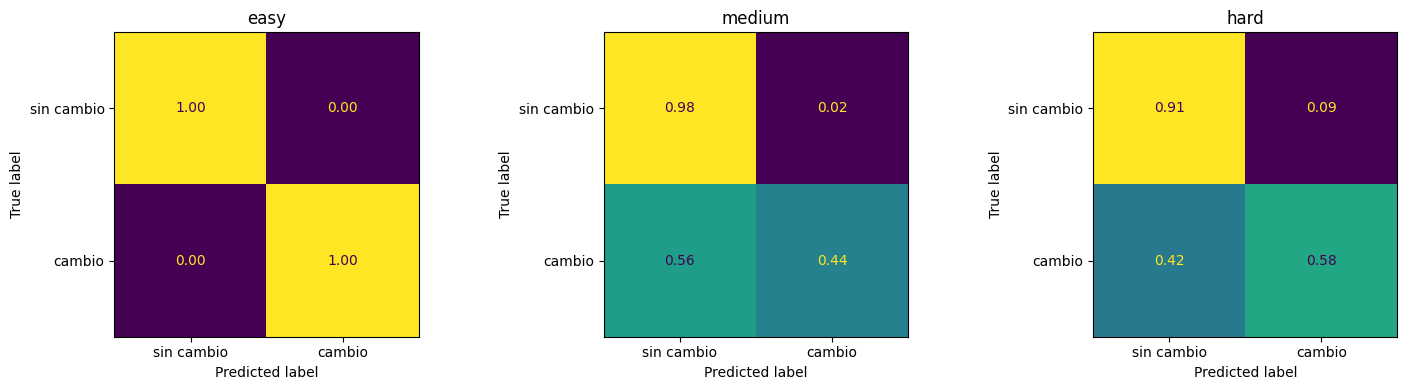

In [92]:
report_test(test_pred_v5, best_per_diff_v5)

### Resultado de la iteración 5

_(Se completa tras ejecutar: cuánto aportan los juicios cruzados y la segunda pasada en validación, resultado en test frente a la iteración 4 y si se acerca al objetivo de 0,75 en *medium* y *hard*.)_

## 13. Comparación de las iteraciones

Se comparan las cinco iteraciones en test con su mejor variante (umbral por dificultad ajustado en validación), con atención a los **falsos negativos**, que eran el problema principal de la iteración 1.

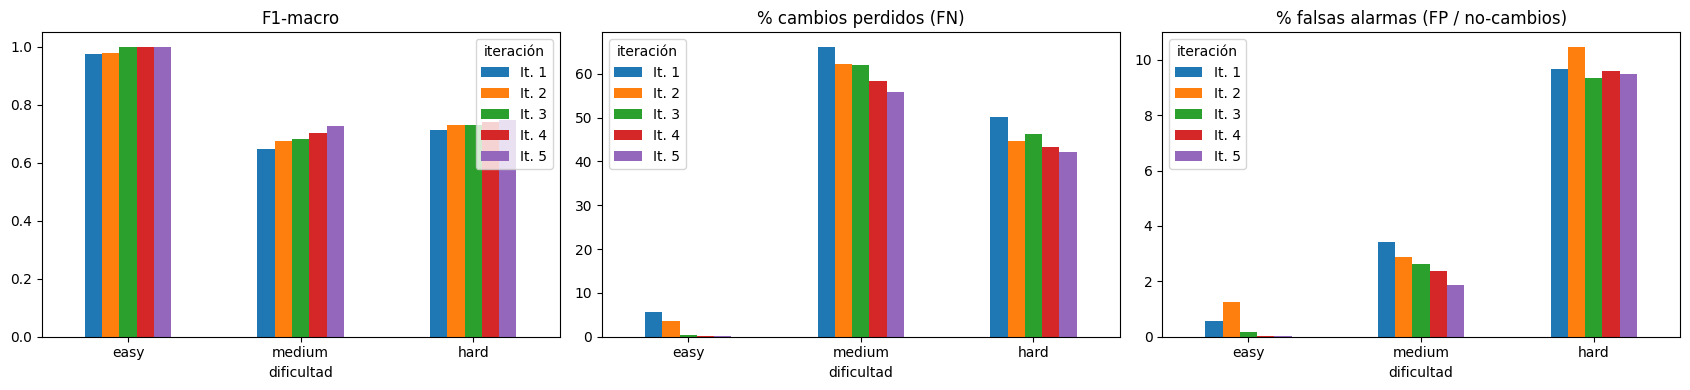

F1-macro                             % cambios perdidos (FN)  \
iteración     It. 1  It. 2  It. 3  It. 4  It. 5                   It. 1   
dificultad                                                                
easy          0.975  0.977  0.997  0.999  0.999                   5.691   
medium        0.645  0.674  0.680  0.702  0.727                  66.129   
hard          0.712  0.729  0.731  0.742  0.748                  50.103   

                                           % falsas alarmas (FP / no-cambios)  \
iteración    It. 2   It. 3   It. 4   It. 5                              It. 1   
dificultad                                                                      
easy         3.614   0.298   0.114   0.134                              0.569   
medium      62.176  62.069  58.306  55.875                              3.435   
hard        44.642  46.300  43.326  42.181                              9.654   

                                         
iteración    It. 2  It. 3  It. 4  It. 5  
dificultad                               
easy         1.254  0.181  0.039  0.026  
medium       2.877  2.618  2.376  1.860  
hard        10.464  9.353  9.606  9.478

In [93]:
rows = []
for name, (probs, pred) in PREDS.items():
    for d in DIFFICULTIES:
        m = (test_df.difficulty == d).values
        y, p = test_df.label.values[m], pred[m]
        rows.append({"iteración": name, "dificultad": d, "F1-macro": macro_f1(y, p),
                     "% cambios perdidos (FN)": 100 * ((p == 0) & (y == 1)).sum() / y.sum(),
                     "% falsas alarmas (FP / no-cambios)": 100 * ((p == 1) & (y == 0)).sum() / (y == 0).sum()})
comparison = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, metric in zip(axes, ["F1-macro", "% cambios perdidos (FN)", "% falsas alarmas (FP / no-cambios)"]):
    comparison.pivot(index="dificultad", columns="iteración", values=metric).reindex(DIFFICULTIES).plot.bar(ax=ax, rot=0)
    ax.set_title(metric)
plt.tight_layout()
plt.show()
comparison.pivot(index="dificultad", columns="iteración").reindex(DIFFICULTIES).round(3)

## 14. Costes computacionales y comparación con el estado del arte

In [94]:
pd.DataFrame(COSTS)

,qué,segundos,memoria pico (GB),pares de train,épocas,batch físico,pares/s
0,It. 1 · fine-tuning,1944,3.18,120000.0,2.0,32.0,123.4
1,It. 1 · inferencia validación completa,1765,0.83,NaN,NaN,NaN,296.8
2,It. 2 · fine-tuning,2253,3.19,240000.0,1.0,32.0,106.5
3,It. 2 · inferencia test completo,1609,0.83,NaN,NaN,NaN,325.5
4,It. 3 · fine-tuning,8686,3.18,240000.0,1.0,32.0,27.6
5,It. 3 · inferencia test completo,2202,0.83,NaN,NaN,NaN,237.9
6,It. 4 · inferencia RoBERTa it. 3 en validación completa,1667,0.83,NaN,NaN,NaN,314.2
7,It. 4 · 2º nivel (rasgos + entrenamiento + test),115,NaN,NaN,NaN,NaN,NaN
8,It. 5 · inferencia pares a distancia 2 (val),1730,0.83,NaN,NaN,NaN,298.9
9,It. 5 · inferencia pares a distancia 3 (val),1621,0.83,NaN,NaN,NaN,314.7


**Comparación con resultados publicados** (se completa en el paso de evaluación): la tabla de resultados del *overview* de PAN de Multi-Author Writing Style Analysis (ediciones 2025/2026) y de los *notebooks* de los participantes, junto a los F1 por dificultad obtenidos aquí.

In [95]:
# Tabla resumen lista para copiar en la primera celda del notebook
board = pd.DataFrame(SCOREBOARD)
cols = ["F1 easy", "F1 medium", "F1 hard", "F1 medio"]
lines = ["| # | Iteración | Experimento | Entrenamiento | " + " | ".join(cols) + " | Conclusión |",
         "|---|---|---|---|" + "---|" * len(cols) + "---|"]
for i, r in board.iterrows():
    lines.append(f"| {i} | {r['iteración']} | {r['experimento']} | {r['entrenamiento']} | "
                 + " | ".join(f"{r[c]:.4f}" for c in cols) + f" | {r['conclusión'] or '_completar_'} |")
print("\n".join(lines))
board.to_csv(RESULTS_DIR / "scoreboard.csv", index=False)

| # | Iteración | Experimento | Entrenamiento | F1 easy | F1 medium | F1 hard | F1 medio | Conclusión |
|---|---|---|---|---|---|---|---|---|
| 0 | — | Baseline: siempre «sin cambio» | — | 0.4100 | 0.4889 | 0.4411 | 0.4467 | Cota inferior trivial |
| 1 | — | Baseline: aleatorio estratificado | tasa de cambios de train | 0.4984 | 0.4993 | 0.5004 | 0.4994 | Azar informado: F1 ≈ 0,5 |
| 2 | 1 | RoBERTa-base pares (umbral 0,5) | 40,000 pares/dif. (natural), 2 épocas, pesos de clase | 0.9553 | 0.6270 | 0.7014 | 0.7612 | Easy casi resuelto; en medium y hard se pierde más de la mitad de los cambios (FN) |
| 3 | 1 | RoBERTa-base pares (umbral global 0.68) | 40,000 pares/dif. (natural), 2 épocas, pesos de clase | 0.9609 | 0.6384 | 0.6921 | 0.7638 | Un único umbral no sirve: mejora easy/medium y empeora hard |
| 4 | 1 | RoBERTa-base pares (umbral por dificultad) | 40,000 pares/dif. (natural), 2 épocas, pesos de clase | 0.9745 | 0.6454 | 0.7117 | 0.7772 | Mejor de la it. 1; umbrales muy distintos

## 15. Conclusiones

**Iteración 1.** El *cross-encoder* RoBERTa-base resuelve casi por completo *easy* (F1 0,97), donde el cambio de tema delata el cambio de autor. En *medium* (0,65) y *hard* (0,71) pierde la mayoría de los cambios. El diagnóstico (sección 7) atribuye el problema sobre todo a los datos (muy pocos positivos en la muestra) y a la falta de calibración por dificultad, no a la capacidad del modelo.

**Iteración 2.** Atacar el problema por el lado de los datos funciona:
- Con más positivos (35 %) y el doble de pares distintos en una sola época, el F1 medio sube de 0,777 a 0,793.
- Bajan los falsos negativos de *medium* (66 % → 62 %) y de *hard* (50 % → 45 %).
- Mantener la cabeza en fp32 elimina la cuantización de las probabilidades y permite ajustar el umbral con precisión.
- El precio es que el modelo queda descalibrado respecto a la distribución real, así que el umbral por dificultad ajustado en validación se vuelve imprescindible.

**Iteración 3.** Darle la dificultad como prefijo es el cambio más rentable:
- Un token más por par sube el F1 medio a **0,803**, el mejor resultado de la práctica.
- Acerca los umbrales a 0,5.
- Deja *easy* prácticamente resuelto (F1 0,997).

**Conclusión global.** El *cross-encoder* RoBERTa-base mejora mucho a los baselines (de 0,45–0,50 a 0,80 de F1 medio), con un coste asumible en una GPU de 4 GB (unos 35 min de entrenamiento con bf16, padding dinámico y batch elegido por memoria). Los F1 finales son:
- ***Easy*: 0,997.** Está resuelto porque el cambio de tema delata el cambio de autor.
- ***Hard*: 0,731.** Con el tema controlado, solo queda el estilo y dos oraciones dan muy poca señal.
- ***Medium*: 0,680.** Es la más difícil: tiene la variedad temática baja de *hard* y además solo un 4 % de cambios, lo que hunde el F1 de la clase positiva (≈ 0,39).

Las tres iteraciones apenas mueven *medium* y *hard* (+3,5 y +1,9 puntos en total frente a +2,3 en *easy*). El techo no lo ponen los hiperparámetros sino la **información de entrada**.

**Trabajo futuro**, por orden de impacto esperado:
1. **Más contexto.** Dar al modelo varias oraciones a cada lado del punto de corte, o clasificar todas las fronteras de un documento a la vez, para comparar estilos sobre más texto.
2. **Más datos.** Usar más del ~10 % de los pares de `train` que se han usado (240.000 de 2,4 M), con varias épocas.
3. **Un modelo más fuerte en rasgos de estilo.** Por ejemplo DeBERTa-v3, o rasgos estilométricos explícitos (puntuación, longitud, palabras funcionales) combinados con el *embedding*.
4. **Medir la varianza entre semillas.** Saber si las diferencias de menos de un punto en *medium* y *hard* son significativas.

El diagnóstico de la iteración 3 (sección 10) concreta estas líneas y la **iteración 4** (sección 11) prueba las de más contexto y rasgos de estilo explícitos sin reentrenar RoBERTa.

**Iteración 4.** El modelo de segundo nivel sube el F1 medio a **0,814** (*medium* 0,702, *hard* 0,742) **sin reentrenar RoBERTa**:
- Combina la probabilidad de RoBERTa con el contexto del documento y rasgos de estilo explícitos.
- Se entrena con la validación mediante validación cruzada agrupada por documento.
- Es la mayor ganancia en *medium* y *hard* desde la iteración 2 (+2,2 y +1,1 puntos).
- Su estimación en validación coincide con el test.
- La ablación muestra dos mecanismos distintos: el **contexto del documento** ayuda en *medium*, donde los segmentos de autor son largos, y solo el **estilo explícito** ayuda en *hard*, donde los autores se alternan casi cada oración.
- Los rasgos de estilo de una sola oración son débiles. La señal fuerte sigue siendo RoBERTa, y en esta iteración solo se le pregunta por un par por frontera. Esto motiva la iteración 5.

**Iteración 5.** _(Se completa tras ejecutar.)_